<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</center></font>
<center><font size=6>MLS 2 - Decision Tree</center></font>

<center><p float="center">
  <img src="https://images.pexels.com/photos/30335251/pexels-photo-30335251.jpeg" alt="health-insurance" width="640"/>
</p></center>
<center><font size=6>Machine Failure Prediction</center></font>

# **Problem Statement**


## Business Context

AutoMobi Engineering Pvt. Ltd is a California-based Tier-1 auto-component manufacturer supplying precision parts to several domestic and export engine OEMs. Its main facility runs around 40 CNC machines across multiple machining shops on a three-shift schedule. The fuel-injector-nozzle shop - the focus of this case - operates roughly 12 CNC machines that turn, drill, and finish nozzles to micron tolerances, producing on the order of 10,000 nozzles a day against committed OEM delivery windows.

Each machine runs near-continuously across shifts, with operating parameters such as spindle speed, torque, tool wear, and machining-zone temperatures logged hourly by recently installed sensors. A sample of about 10,000 of these hourly readings from the past quarter is now available, and within it, failure conditions appear in only about 3–4% of records - rare, but disruptive. Until now, that data has sat largely unused: machine health is judged by fixed-interval preventive maintenance and quick manual inspections between shifts, with an experienced maintenance team relying on schedules and gauge readings rather than the sensor history.

Over the last quarter, the shop has seen a sharp rise in unplanned failures mid-shift, on the order of 30+ stoppages a month, up from a handful in previous months. Because failures strike without warning, a worn tool or overstrained spindle is typically caught only after it has scrapped a batch of in-process nozzles and halted the line for two to four hours. The fixed-schedule approach compounds this from both ends: it services healthy machines that did not need attention while still missing the ones that fail between scheduled checks.

- 30+ unplanned stoppages a month, each idling a line for roughly 2–4 hours (totaling ~90 lost machine-hours, or about 1% of the shop's ~8,640 monthly machine-hours), concentrated in costly, unplanned bursts that force emergency tool and spare changes.
- Scrapped in-process nozzles and rework on micron-tolerance parts at each stoppage, steadily eroding yield.
- Missed or at-risk OEM delivery windows, exposing the plant to penalty clauses and reputational risk with key customers.
- Over-servicing of healthy machines under the fixed-interval regime, leading to spares and labor spent where no fault existed.
- Constant firefighting for the maintenance team: reacting to breakdowns rather than planning interventions, with no way to tell from the shop floor which machine is about to fail.

## Objective

AutoMobi has commissioned a predictive-maintenance pilot in the injector-nozzle shop, drawing on three months of collected sensor data, to move the shop from reactive, schedule-based upkeep to early, condition-based intervention.

- To read each machine's operating parameters and flag the ones likely to fail in the near term, allowing maintenance to act before a breakdown rather than after, thereby directly cutting unplanned downtime and scrap.
- To surface which operating conditions most drive failure, giving engineering clear, defensible thresholds to monitor instead of relying on intuition.
- To distinguish genuinely at-risk machines from healthy ones so servicing, spares, and inspection effort are spent where they matter, replacing blanket fixed-interval maintenance with targeted action.
- To translate the findings into a costed maintenance plan management can act on, quantifying savings from avoided downtime, reduced scrap, and right-sized servicing.

## Data Description

The dataset consists of the following attributes:

- **UDI**: Unique identifier ranging from 1 to 10000.
- **Type**: Product quality variant  low (`L`, 60% of products), medium (`M`, 30%), and high (`H`, 10%).
- **Air temperature**: Ambient temperature in the machine shop, measured in Kelvin.
- **Process temperature**: Tool-tip temperature, measured in Kelvin.
- **Rotational speed**: Rotational speed of the machine spindle, in revolutions per minute (rpm).
- **Torque**: Torque acting on the machine spindle, in Newton metres (Nm).
- **Tool wear**: Wear on the cutting face of the tool, in micrometres (continuous rubbing of the tool on the workpiece wears the tool material).
- **Failure**: Target variable  `0` = no failure, `1` = failure.

# **Installing and Importing Necessary Libraries**


In [1]:
!pip install pandas==2.2.2\
             numpy==2.0.2\
             matplotlib==3.10.0\
             seaborn==0.13.2\
             scikit-learn==1.6.1\
             scipy==1.16.3

  Using cached pandas-2.2.2.tar.gz (4.4 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached numpy-2.0.2.tar.gz (18.9 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... error
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [636 lines of output]
      + /Users/sahithid/Desktop/repos/.venv/bin/python3.13 /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-wq8xbs3f/numpy_e78f80ad55b64931b2ebc44b70286bc7/vendored-meson/meson/meson.py setup /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-wq8xbs3f/numpy_e78f80ad55b64931b2ebc44b70286bc7 /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-wq8xb

In [2]:
%pip install -U pip

%pip install \
  "pandas>=2.2.3" \
  "numpy>=2.1.0" \
  "matplotlib>=3.10.0" \
  "seaborn>=0.13.2" \
  "scikit-learn>=1.6.1" \
  "scipy>=1.16.3"

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

***Prompt***:

<font size=3 color="#4682B4">Generate a Python import cell for a Decision Tree classification case study, including data handling, visualization, train/validation/test splitting, the DecisionTreeClassifier, classification evaluation metrics (recall, precision, F1, accuracy, ROC-AUC), confusion matrix and curve utilities, tree plotting, and warning suppression. Add concise comments and return only code.
</font>

In [3]:
# Import libraries for reading and manipulating data
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import the model
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Import utilities for data splitting
from sklearn.model_selection import train_test_split

# Import classification evaluation metrics
from sklearn.metrics import (
    recall_score, precision_score, f1_score, accuracy_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, precision_recall_curve
)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# **Loading the Data**

With the libraries in place, we load the sensor dataset. It contains hourly readings from the injector nozzle shop  product quality variant, ambient and tool-tip temperatures, spindle speed and torque, tool wear, and whether the machine failed.

***Prompt***:

<font size=3 color="#4682B4">Load the machine_failure_data.csv file and store it as data.
</font>

In [6]:
data = pd.read_csv('./content/machine_failure_data.csv')

# **Data Overview**

Before any analysis, we understand the structure and content of the dataset: its size, a look at the rows, the data types, and basic descriptive statistics.

***Prompt***:

<font size=3 color="#4682B4">Display the shape of data.
</font>

In [7]:
data.shape

(10000, 8)

The dataset consists of **10,000 rows** and **8 columns**.

***Prompt***:

<font size=3 color="#4682B4">Display the first 10 rows of the data.
</font>

In [8]:
data.head(10)

,UDI,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure
0,1,M,298.1,323.740741,1551,42.8,0,0
1,2,L,298.2,324.111111,1408,46.3,3,0
2,3,L,298.1,323.370370,1498,49.4,5,0
3,4,L,298.2,323.740741,1433,39.5,7,0
4,5,L,298.2,324.111111,1408,40.0,9,0
5,6,M,298.1,323.740741,1425,41.9,11,0
6,7,L,298.1,323.740741,1558,42.4,14,0
7,8,L,298.1,323.740741,1527,40.2,16,0
8,9,M,298.3,324.111111,1667,28.6,18,0
9,10,M,298.5,325.222222,1741,28.0,21,0


***Prompt***:

<font size=3 color="#4682B4">Display the last 10 rows of the data.
</font>

In [9]:
data.tail(10)

,UDI,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure
9990,9991,L,298.8,323.370370,1527,36.2,3,0
9991,9992,M,298.9,323.000000,1827,26.1,5,0
9992,9993,L,298.8,323.000000,1484,39.2,8,0
9993,9994,L,298.8,323.000000,1401,47.3,10,0
9994,9995,L,298.8,322.629630,1634,27.9,12,0
9995,9996,M,298.8,323.000000,1604,29.5,14,0
9996,9997,H,298.9,323.000000,1632,31.8,17,0
9997,9998,M,299.0,323.740741,1645,33.4,22,0
9998,9999,H,299.0,324.111111,1408,48.5,25,0
9999,10000,M,299.0,324.111111,1500,40.2,30,0


***Prompt***:

<font size=3 color="#4682B4">Display the column names, data types, and number of non-null entries in the data.
</font>

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UDI                  10000 non-null  int64  
 1   Type                 10000 non-null  str    
 2   Air temperature      10000 non-null  float64
 3   Process temperature  10000 non-null  float64
 4   Rotational speed     10000 non-null  int64  
 5   Torque               10000 non-null  float64
 6   Tool wear            10000 non-null  int64  
 7   Failure              10000 non-null  int64  
dtypes: float64(3), int64(4), str(1)
memory usage: 625.1 KB


- The dataset has **8 columns** and **10,000 rows**, with **no missing values**.
- Data types are as expected:
  - **Numeric:** `UDI`, `Air temperature`, `Process temperature`, `Rotational speed`, `Torque`, `Tool wear`, `Failure`
  - **Categorical:** `Type`

***Prompt***:

<font size=3 color="#4682B4">Display the statistical summary of the numerical columns.
</font>

In [11]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.500000,2886.895680,1.0,2500.750000,5000.500000,7500.25,10000.0
Air temperature,10000.0,300.004930,2.000259,295.3,298.300000,300.100000,301.50,304.5
Process temperature,10000.0,328.946519,5.495312,313.0,324.481481,329.296296,333.00,343.0
Rotational speed,10000.0,1538.776100,179.284096,1168.0,1423.000000,1503.000000,1612.00,2886.0
Torque,10000.0,39.986910,9.968934,3.8,33.200000,40.100000,46.80,76.6
Tool wear,10000.0,107.951000,63.654147,0.0,53.000000,108.000000,162.00,253.0
Failure,10000.0,0.033900,0.180981,0.0,0.000000,0.000000,0.00,1.0


**Observations:**
1. **Temperatures:** Air temperature averages ~**300 K** (295–305 K); process temperature averages ~**329 K** (313–343 K)  the tool tip runs consistently hotter than the ambient shop, as expected.
2. **Rotational speed:** Centred around ~**1,500 rpm** but reaching **2,886 rpm**  a long right tail.
3. **Torque:** Roughly symmetric around ~**40 Nm** (4–77 Nm).
4. **Tool wear:** Spread fairly evenly from **0 to 253 µm** (mean ~108).
5. **Failure:** Mean of ~**0.034**  only about **3.4%** of records are failures. This imbalance drives the entire modeling strategy below.

***Prompt***:

<font size=3 color="#4682B4">Display the summary of the categorical column.
</font>

In [12]:
data.describe(include='object')

,Type
count,10000
unique,3
top,L
freq,6000


**Observation:**
- The `Type` column has 3 quality variants. As stated in the data description, **L (low)** dominates at ~60%, followed by **M (medium)** ~30% and **H (high)** ~10%.

***Prompt***:

<font size=3 color="#4682B4">How many duplicate rows are present in the data?
</font>

In [13]:
# Identify duplicate rows
duplicate_rows = data[data.duplicated()]

# Print the number of duplicate rows
print(f"Number of duplicate rows: {len(duplicate_rows)}")

Number of duplicate rows: 0


There are **no duplicate rows** in the data.

***Prompt***:

<font size=3 color="#4682B4">Show the count of missing values in each column.
</font>

In [14]:
data.isnull().sum()

UDI                    0
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Failure                0
dtype: int64

**Observation:** No column has any missing values, so no imputation is required.

# **Exploratory Data Analysis**

**Note: The EDA section has been covered multiple times in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the appendix section.**

With a basic understanding of our dataset, it's time to dive deeper through Exploratory Data Analysis (EDA). This step is crucial for uncovering hidden patterns and relationships between features.

## Univariate Analysis

### Failure

***Prompt***:

<font size=3 color="#4682B4">Visualize the class balance of the Failure column as counts and percentages.
</font>

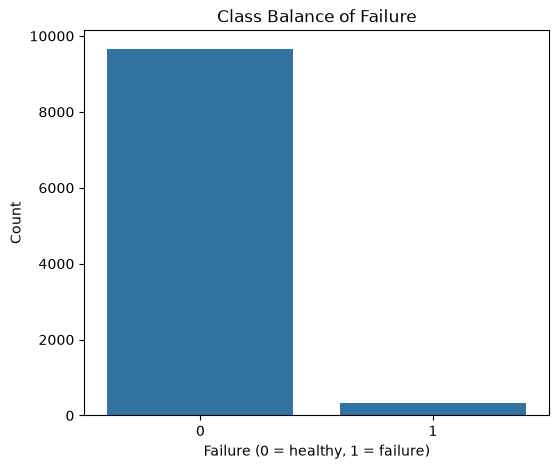

Failure
0    9661
1     339
Name: count, dtype: int64
Failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [15]:
# Class balance of the target
plt.figure(figsize=(6, 5))
ax = sns.countplot(x='Failure', data=data)
plt.title('Class Balance of Failure')
plt.xlabel('Failure (0 = healthy, 1 = failure)')
plt.ylabel('Count')
plt.show()

print(data['Failure'].value_counts())
print((data['Failure'].value_counts(normalize=True) * 100).round(2))

**Observation:** The data is **severely imbalanced**  only ~**3.4%** of records are failures (339 of 10,000). This single fact reshapes everything: a model that blindly predicts *no failure* every time would be ~96.6% accurate and **completely useless**, because it would never flag a single failing machine. Accuracy is therefore the wrong yardstick; **recall on the failure class** is what matters.

### Type

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of the Type (product quality) column.
</font>

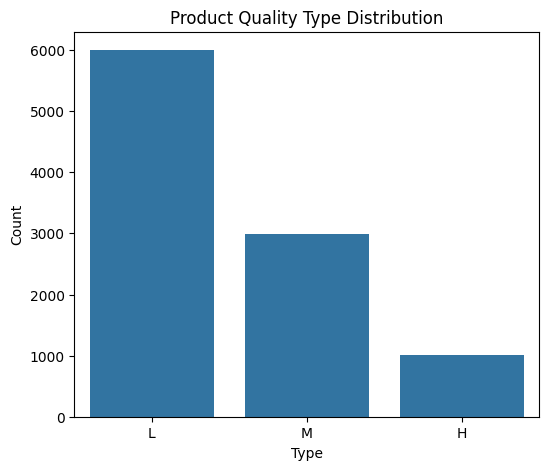

In [ ]:
plt.figure(figsize=(6, 5))
sns.countplot(x='Type', data=data, order=['L', 'M', 'H'])
plt.title('Product Quality Type Distribution')
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()

**Observation:** As expected, **L (low quality)** is the most common variant, then **M**, then **H**  the 60 / 30 / 10 split described in the data dictionary.

### Rotational Speed

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of Rotational speed.
</font>

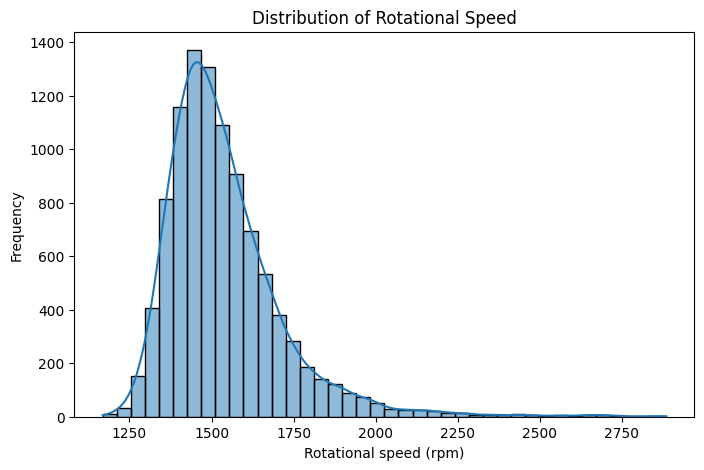

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data['Rotational speed'], bins=40, kde=True)
plt.title('Distribution of Rotational Speed')
plt.xlabel('Rotational speed (rpm)')
plt.ylabel('Frequency')
plt.show()

**Observation:** Rotational speed is **right-skewed**  most readings cluster near ~1,400–1,600 rpm with a long tail toward higher speeds. Trees handle skew without transformation, so no action is needed.

### Torque and Tool wear

***Prompt***:

<font size=3 color="#4682B4">Visualize the distributions of Torque and Tool wear side by side.
</font>

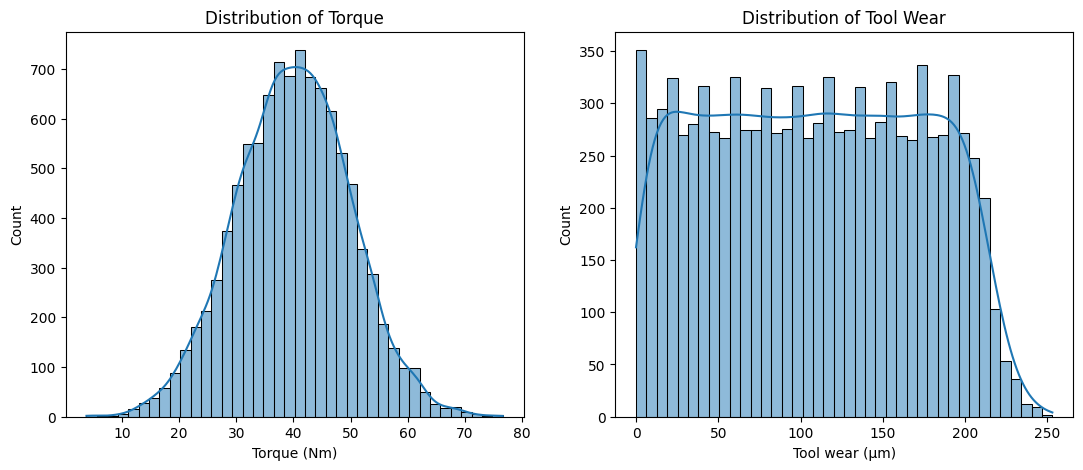

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data['Torque'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Torque')
axes[0].set_xlabel('Torque (Nm)')
sns.histplot(data['Tool wear'], bins=40, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Tool Wear')
axes[1].set_xlabel('Tool wear (µm)')
plt.show()

**Observation:** **Torque** is roughly symmetric around ~40 Nm. **Tool wear** is spread fairly evenly from 0 to ~253 µm, consistent with tools being cycled through their full service life.

## Bivariate Analysis

### Failure vs Torque

***Prompt***:

<font size=3 color="#4682B4">Compare the distribution of Torque for failed vs healthy machines using a box plot.
</font>

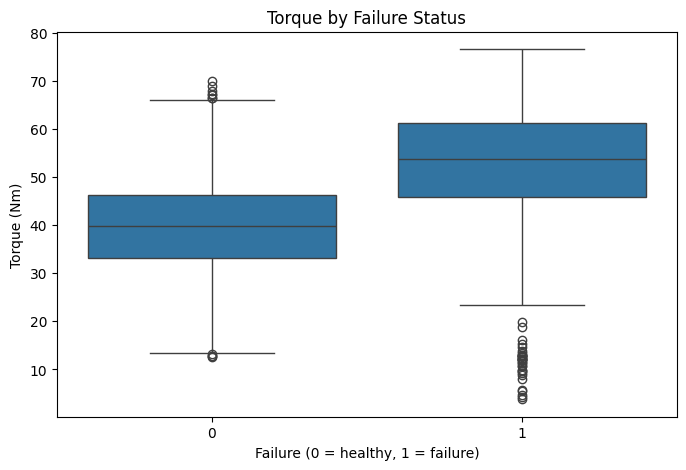

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Failure', y='Torque', data=data)
plt.title('Torque by Failure Status')
plt.xlabel('Failure (0 = healthy, 1 = failure)')
plt.ylabel('Torque (Nm)')
plt.show()

**Observation:** Failed machines tend to operate at **noticeably higher torque** (median ~50 Nm vs ~40 Nm for healthy machines). Torque is one of the strongest single signals of failure.

### Failure vs Tool wear

***Prompt***:

<font size=3 color="#4682B4">Compare the distribution of Tool wear for failed vs healthy machines using a box plot.
</font>

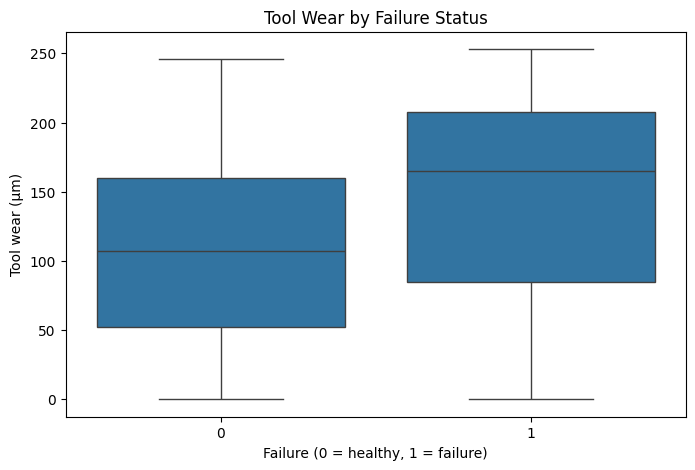

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Failure', y='Tool wear', data=data)
plt.title('Tool Wear by Failure Status')
plt.xlabel('Failure (0 = healthy, 1 = failure)')
plt.ylabel('Tool wear (µm)')
plt.show()

**Observation:** Failures are associated with **higher tool wear** (median ~144 µm vs ~107 µm). Worn tools are more likely to fail  physically intuitive.

### Failure vs Rotational speed

***Prompt***:

<font size=3 color="#4682B4">Compare the distribution of Rotational speed for failed vs healthy machines using a box plot.
</font>

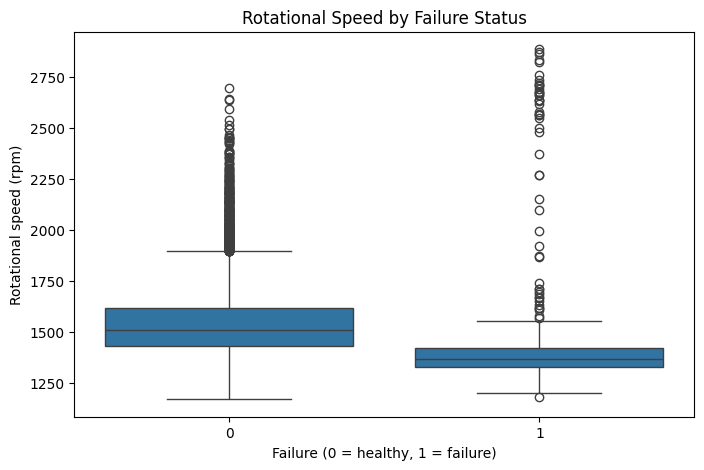

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Failure', y='Rotational speed', data=data)
plt.title('Rotational Speed by Failure Status')
plt.xlabel('Failure (0 = healthy, 1 = failure)')
plt.ylabel('Rotational speed (rpm)')
plt.show()

**Observation:** Failed machines run at **slightly lower spindle speeds** on average. Combined with their higher torque, this points to a load-related failure mode (low speed + high torque = high mechanical strain).

### Failure vs Type

***Prompt***:

<font size=3 color="#4682B4">Compute and plot the failure rate (%) within each product Type, with the count of failures per group.
</font>

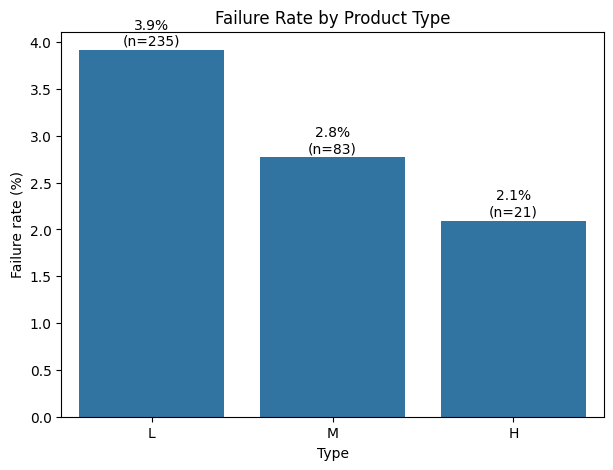

In [ ]:
rate = data.groupby('Type')['Failure'].mean().mul(100).reindex(['L', 'M', 'H'])
counts = data.groupby('Type')['Failure'].sum().reindex(['L', 'M', 'H'])

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=rate.index, y=rate.values)
for i, (r, c) in enumerate(zip(rate.values, counts.values)):
    ax.text(i, r + 0.05, f'{r:.1f}%\n(n={int(c)})', ha='center')
plt.title('Failure Rate by Product Type')
plt.xlabel('Type')
plt.ylabel('Failure rate (%)')
plt.show()

**Observation:** **Low-quality (L)** products fail the most (~ 3.9%), high-quality (H) the least (~2.1%). There is a real gradient, but it is mild compared with the sensor signals  worth noting as we watch whether `Type` ends up mattering to the model.

## Correlation Heatmap

***Prompt***:

<font size=3 color="#4682B4">Plot a correlation heatmap of the numerical columns (excluding UDI) together with Failure, and highlight any strong pairwise relationships.
</font>

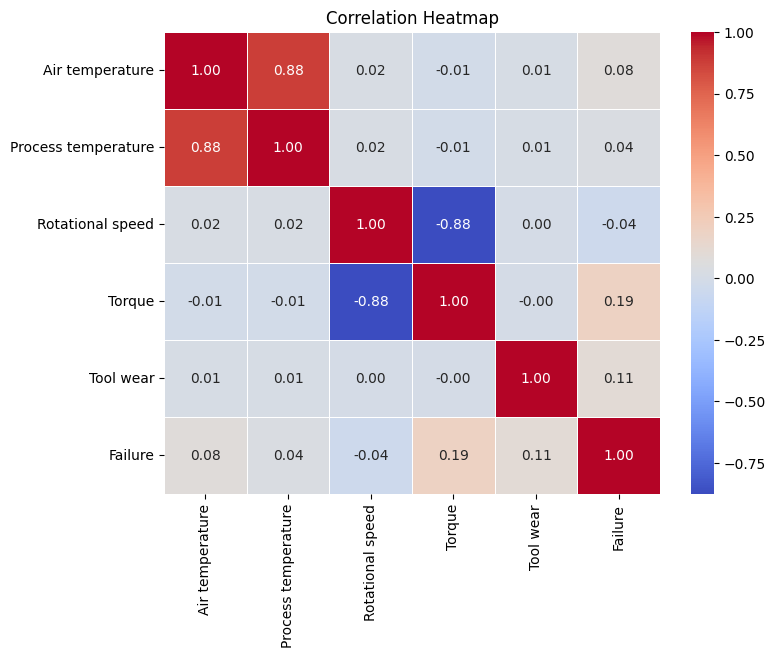

In [ ]:
num_cols = ['Air temperature', 'Process temperature', 'Rotational speed',
            'Torque', 'Tool wear', 'Failure']
corr = data[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

**Observations:**
- **Air temperature & Process temperature are strongly correlated (~0.88)**  they carry nearly the same information. A tree will tend to use one and leave the other largely unused.
- **Rotational speed & Torque are strongly *inversely* related (~−0.88)**  physically expected, since mechanical power is roughly torque × speed, so the two trade off at similar power.
- Among the sensors, **Torque (~0.19)** and **Tool wear (~0.11)** show the strongest (if modest) linear association with failure. Linear correlation understates a tree's reach, though  trees capture interactions and thresholds that a correlation coefficient cannot.

# **Data Preprocessing**

Two steps prepare the data for modeling: encode the categorical `Type` column, and split into training, validation, and test sets.


## Encode the Data

***Prompt***:

<font size=3 color="#4682B4">Drop the UDI identifier, separate the target Failure as Y and the predictors as X, then one-hot encode the categorical column(s) in X with drop_first=True
</font>

**NOTE:** `UDI` is a row identifier with no predictive meaning, so it is dropped. We use `dtype=int` so the dummy columns come out as `0/1` integers rather than booleans, and `drop_first=True` to avoid one redundant column per category.

In [ ]:
# Separate predictors and target, dropping the identifier
X = data.drop(['UDI', 'Failure'], axis=1)
Y = data['Failure']

# One-hot encode the categorical Type column
X = pd.get_dummies(X, drop_first=True, dtype=int)

X.head(10)

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Type_L,Type_M
0,298.1,323.740741,1551,42.8,0,0,1
1,298.2,324.111111,1408,46.3,3,1,0
2,298.1,323.370370,1498,49.4,5,1,0
3,298.2,323.740741,1433,39.5,7,1,0
4,298.2,324.111111,1408,40.0,9,1,0
5,298.1,323.740741,1425,41.9,11,0,1
6,298.1,323.740741,1558,42.4,14,1,0
7,298.1,323.740741,1527,40.2,16,1,0
8,298.3,324.111111,1667,28.6,18,0,1
9,298.5,325.222222,1741,28.0,21,0,1


**Observation:** `Type` expands into `Type_L` and `Type_M` (with `H` as the dropped reference category). All other columns are already numeric, so the feature matrix is now fully numeric and ready for modeling.

## Train / Validation / Test Split

We use a **three-way split**: the model *learns* on the training set, we *choose* pruning settings on the validation set, and we *report final performance once* on the test set. Selecting pruning levels on the test set would use it to make modeling decisions and give optimistically biased results  a separate validation set keeps the test set genuinely untouched until the end.

Because failures are only ~3.4% of the data, we **stratify** on `Failure` so all three splits keep the same failure rate. Split proportions: **70% train / 15% validation / 15% test**.

***Prompt***:

<font size=3 color="#4682B4">Split X and Y into train (70%), validation (15%), and test (15%) sets using random_state=42 and stratifying on Y
</font>

In [ ]:
# First split off the training set (70%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, Y, test_size=0.30, random_state=RANDOM_STATE, stratify=Y
)

# Split the remaining 30% evenly into validation and test (15% each)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

***Prompt***:

<font size=3 color="#4682B4">Print the shape and the failure rate of each split
</font>

In [ ]:
for name, ys in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f"{name:11s} rows: {len(ys):5d}   failure rate: {ys.mean():.4f}")

Train       rows:  7000   failure rate: 0.0339
Validation  rows:  1500   failure rate: 0.0340
Test        rows:  1500   failure rate: 0.0340


**Observation:** All three splits carry an identical ~**3.4%** failure rate, confirming stratification worked. The test set will not be touched again until the **Model Comparison** section.

# **Model Building**

## Model Evaluation Criterion

**Model can make wrong predictions as:**
- Predicting a machine will not fail but in reality, the machine will fail (FN)
- Predicting a machine will fail but in reality, the machine will not fail (FP)

**Which case is more important?**

- If we predict that a machine will not fail but in reality, the machine fails, then the company will have to bear the cost of repair/replacement and also face equipment downtime losses
- If we predict that a machine will fail but in reality, the machine does not fail, then the company will have to bear the cost of inspection
- The inspection cost is generally less compared to the repair/replacement cost

**How to reduce the losses?**

The company would want the recall to be maximized, greater the recall score higher are the chances of minimizing the False Negatives.

## Utility Functions

We define two reusable helpers so every model is scored the same way: `model_performance_classification_sklearn` returns a one-row table of Accuracy, Recall, Precision, and F1, and `confusion_matrix_sklearn` plots a labelled confusion matrix with counts and percentages. At the end we stack each model's tables side by side to compare them.

***Prompt***:

<font size=3 color="#4682B4">Write a function named model_performance_classification_sklearn that takes a fitted classifier, the predictor features, and the true target. It should predict on the predictors, compute accuracy, recall, precision, and F1-score, and return them as a single-row pandas DataFrame with columns "Accuracy", "Recall", "Precision", and "F1". Add a short docstring describing the parameters.
</font>

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

***Prompt***:

<font size=3 color="#4682B4">Write a function named confusion_matrix_sklearn that takes a fitted classifier, the predictor features, and the true target. It should predict on the predictors, compute the confusion matrix, and plot it as a 6×4 seaborn heatmap where each cell is annotated with both the raw count and its percentage of the total (count on the first line, percentage to two decimals on the second). Label the y-axis "True label" and x-axis "Predicted label", and include a short docstring.
</font>

In [ ]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

## Model Building

We build four trees, each adding **one** idea on top of the last, so we can see exactly what each change buys:

1. **Model 1 - Base:** a default tree with no constraints
2. **Model 2 - `class_weight`:** tell the tree that failures matter more, to fight the imbalance.
3. **Model 3 - Pre-pruning:** constrain the tree's growth as it is built.
4. **Model 4 - Post-pruning:** let it grow fully, then trim back with cost-complexity pruning.

For every model we look at the confusion matrix and the performance table on **both** the training set and the held-out **validation** set. The **test set stays sealed** until the final Model Comparison.

### Model 1 - Base Decision Tree

We start with a default `DecisionTreeClassifier` and no constraints. This is intentionally allowed to overfit  it is the starting point that pruning will fix.

***Prompt***:

<font size=3 color="#4682B4">Train a DecisionTreeClassifier with random_state=42 and no other constraints on the training data.
</font>

In [ ]:
model_1 = DecisionTreeClassifier(random_state=RANDOM_STATE)
model_1.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and the performance table for Model 1 on the training set.
</font>

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


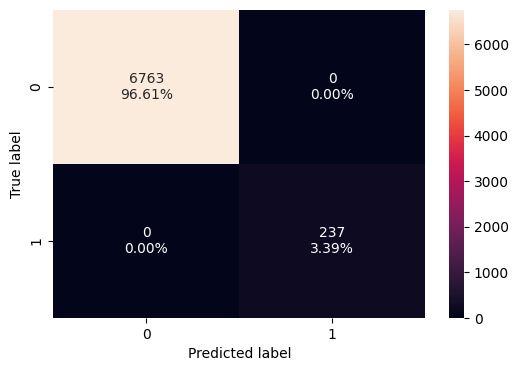

In [ ]:
confusion_matrix_sklearn(model_1, X_train, y_train)
dt_base_perf_train = model_performance_classification_sklearn(model_1, X_train, y_train)
dt_base_perf_train

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and the performance table for Model 1 on the validation set.
</font>

,Accuracy,Recall,Precision,F1
0,0.978,0.745098,0.655172,0.697248


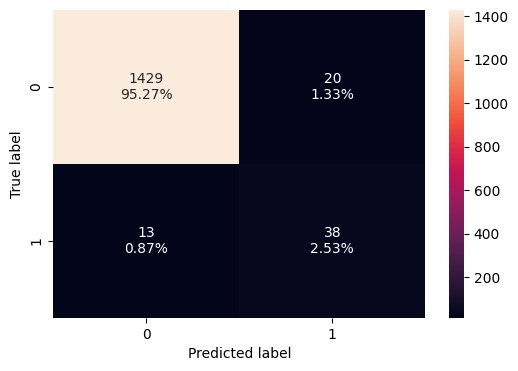

In [ ]:
confusion_matrix_sklearn(model_1, X_val, y_val)
dt_base_perf_val = model_performance_classification_sklearn(model_1, X_val, y_val)
dt_base_perf_val

**Observation:**
- On the **training** set every metric is a perfect **1.0**  the tree has memorised the data, classifying every row correctly.
- On the **validation** set recall drops to ~**0.75** and accuracy is high only because the data is imbalanced. The large train-to-validation gap is the textbook signature of **overfitting**: with ~19 levels and ~145 leaves, the model has learned the training rows rather than a general pattern.

***Prompt***:

<font size=3 color="#4682B4">Visualize the decision tree (Model 1) using plot_tree.
</font>

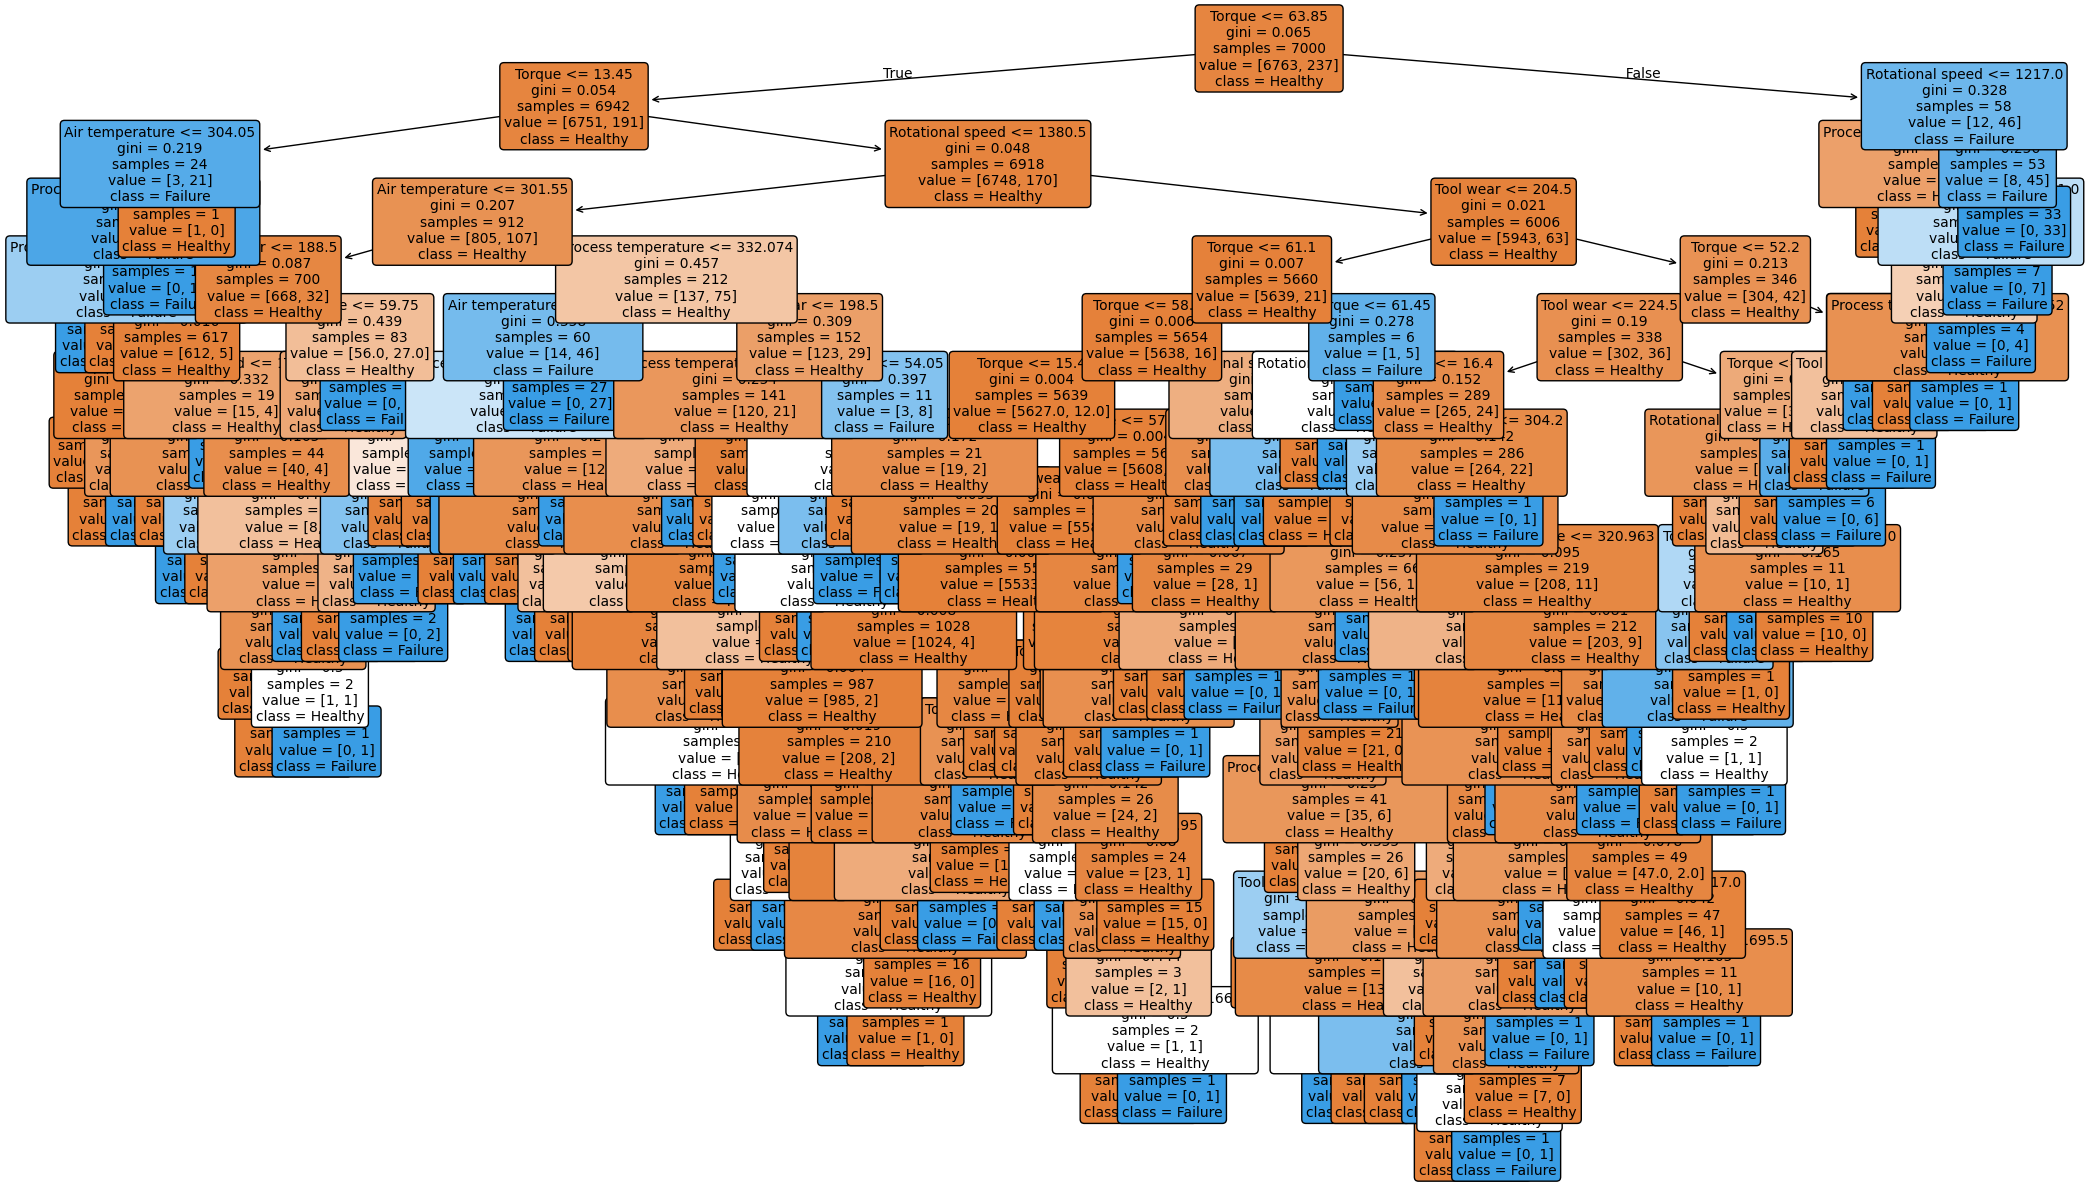

In [ ]:
feature_names = list(X_train.columns)
plt.figure(figsize=(25, 15))
out = plot_tree(model_1, feature_names=feature_names, class_names=['Healthy', 'Failure'],
                filled=True, rounded=True, fontsize=10)
# darken split arrows if matplotlib leaves them faint
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor('black'); arrow.set_linewidth(1)
plt.show()

**Observations:** The decision tree was trained without any depth restriction (max_depth not set), so it has grown until the leaves are almost completely pure. This is visible in the plot as a deep, sprawling structure with many leaf nodes
- Top split: The root node splits on the single most informative feature - the one that best separates Healthy from Failure on its own
- Class imbalance is visible in the colors: Because the dataset has many more Healthy than Failure samples, most of the tree is shaded toward the Healthy class, with smaller, more saturated Failure leaves appearing deeper down after several conditions are stacked.
- Overfitting risk: The tree continues splitting until tiny leaves contain only a handful (sometimes a single) sample. Branches this deep are memorizing noise rather than learning a general rule

### Model 2 - Decision Tree with class_weight

* If the frequency of class A is 10% and the frequency of class B is 90%, the tree will lean toward predicting class B simply because it's more frequent, not because it's easier to separate.

* In this case, we will set `class_weight` = "`balanced`", which will automatically adjust the weights to be inversely proportional to the class frequencies in the input data.

* `class_weight` is a hyperparameter for the decision tree classifier.

***Prompt***:

<font size=3 color="#4682B4">Train a DecisionTreeClassifier with random_state=42 and class_weight='balanced' on the training data.
</font>

In [ ]:
model_2 = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced')
model_2.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and the performance table for Model 2 on the training set.
</font>

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


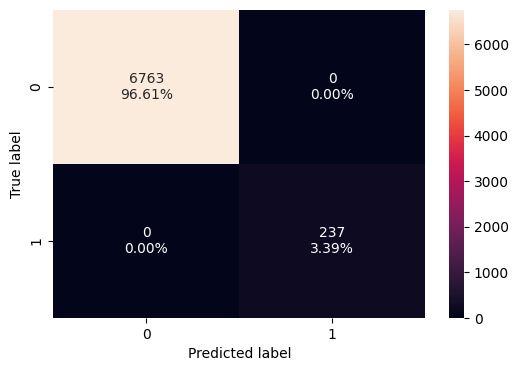

In [ ]:
confusion_matrix_sklearn(model_2, X_train, y_train)
dt_cw_perf_train = model_performance_classification_sklearn(model_2, X_train, y_train)
dt_cw_perf_train

* The model again classifies every training point correctly (recall, precision, and F1 are all 1.0). An unconstrained tree will always drive training error to zero by learning every pattern in the training set  which is exactly what leads to overfitting.

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and the performance table for Model 2 on the validation set.
</font>

,Accuracy,Recall,Precision,F1
0,0.974667,0.54902,0.651163,0.595745


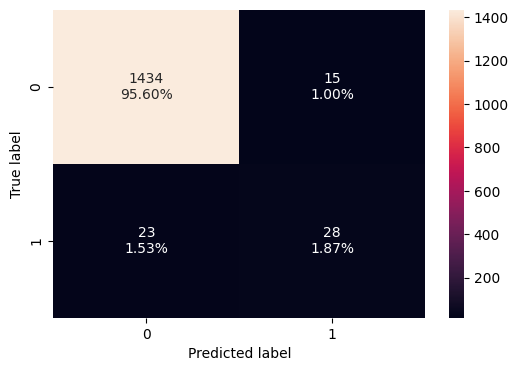

In [ ]:
confusion_matrix_sklearn(model_2, X_val, y_val)
dt_cw_perf_val = model_performance_classification_sklearn(model_2, X_val, y_val)
dt_cw_perf_val

**Observation:**
- There is again a large gap between training and validation performance  the model is overfitting.
- Crucially, `class_weight` **alone does not lift validation recall** here (it can even dip below the base tree), because a fully-grown tree already memorises the training data and re-weighting only reshuffles splits. **The lesson:** weighting pays off only once we also **control how the tree grows**  which is what pre- and post-pruning do next.

***Prompt***:

<font size=3 color="#4682B4">Visualize the decision tree (Model 2) using plot_tree.
</font>

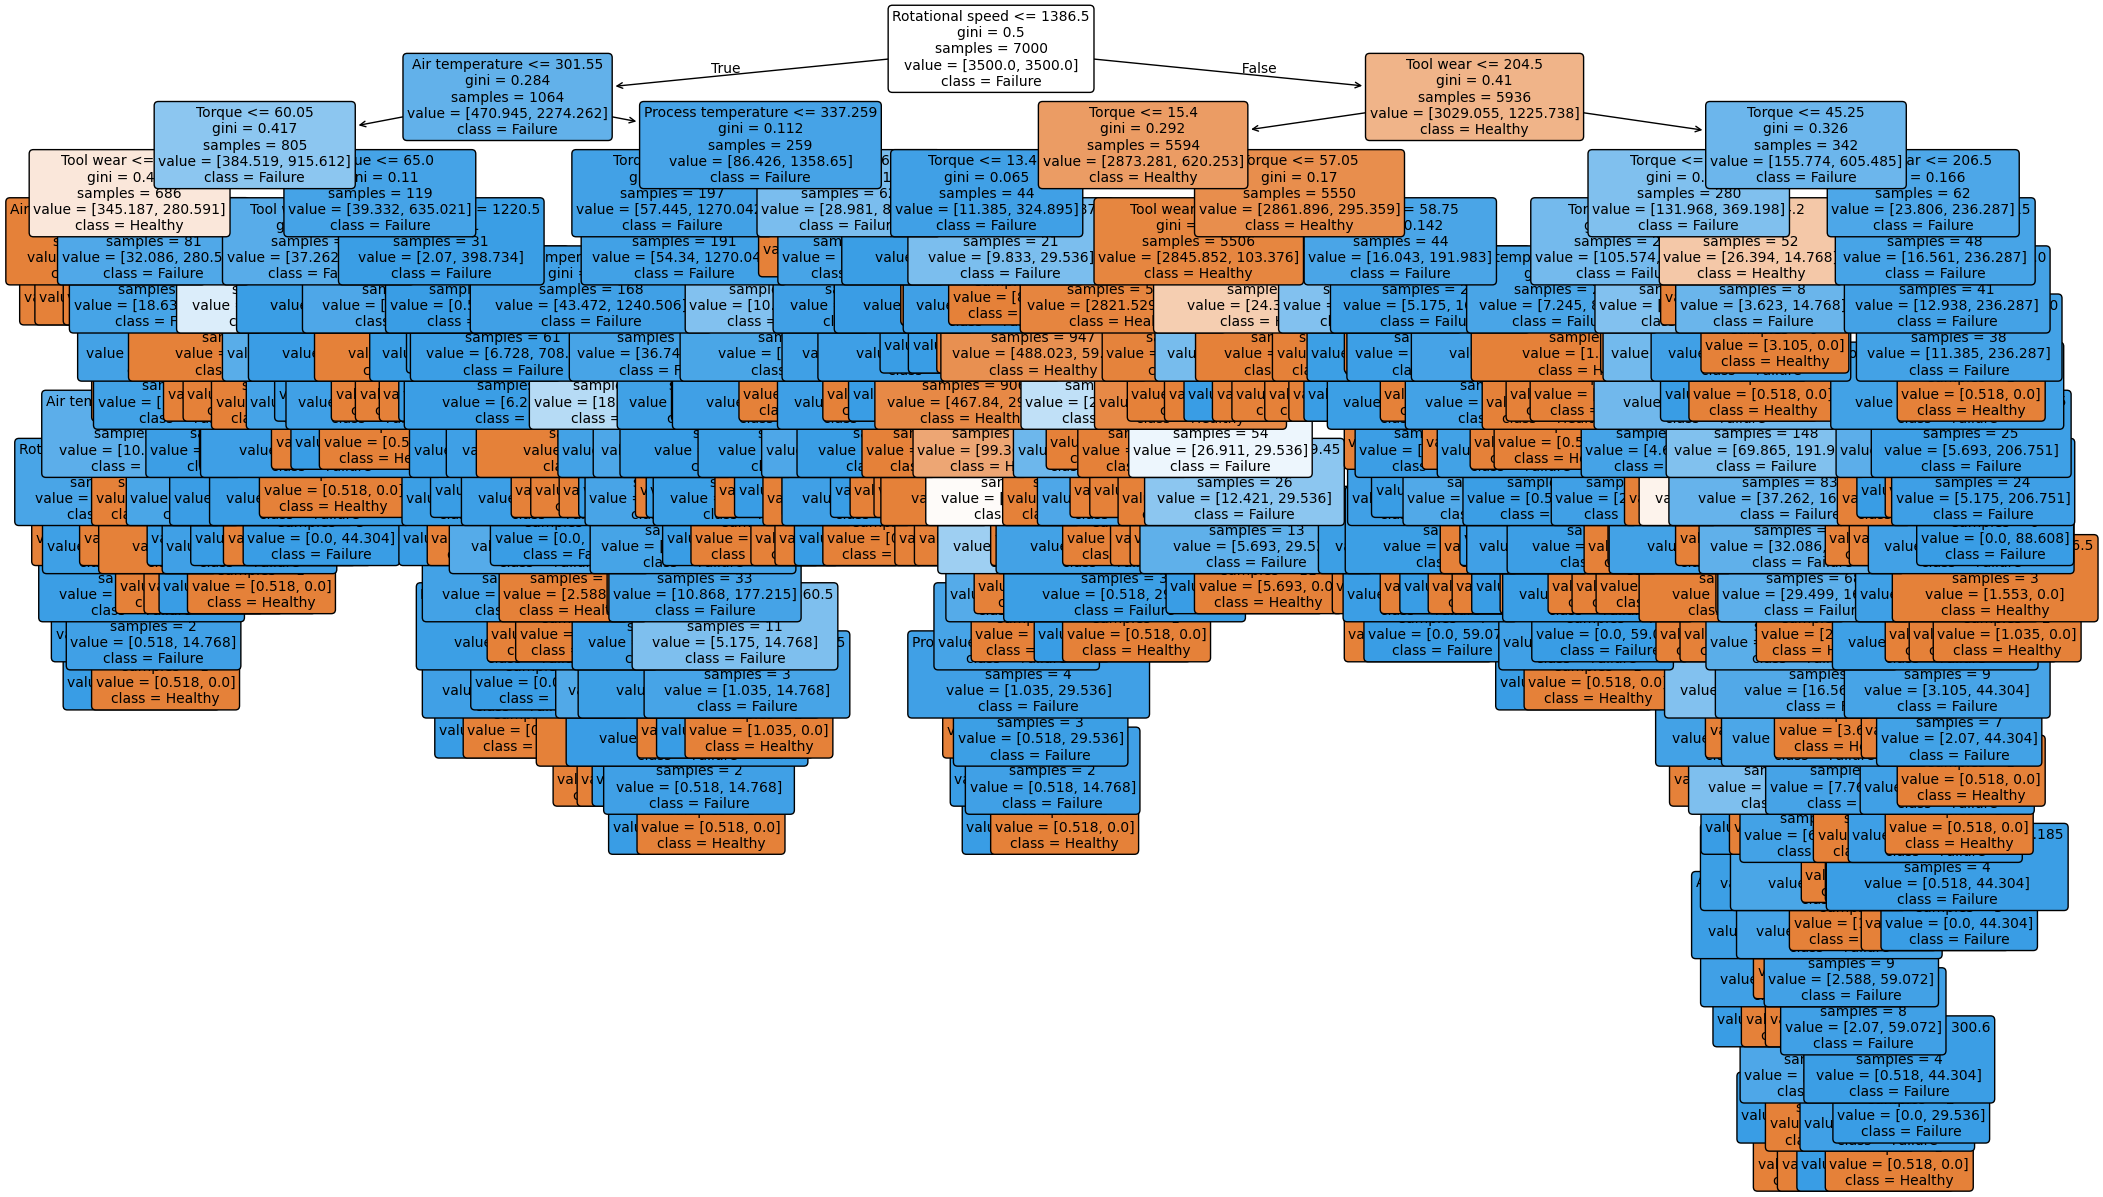

In [ ]:
feature_names = list(X_train.columns)
plt.figure(figsize=(25, 15))
out = plot_tree(model_2, feature_names=feature_names, class_names=['Healthy', 'Failure'],
                filled=True, rounded=True, fontsize=10)
# darken split arrows if matplotlib leaves them faint
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor('black'); arrow.set_linewidth(1)
plt.show()

**Observations:** This second tree is identical to model_1 in setup except that class_weight='balanced' now tells the model to weight each class inversely to its frequency. Because Failure is the minority class, its samples effectively count for more during splitting

### Model 3 - Pre-Pruning

* Hyperparameter tuning is crucial because it directly affects the performance of a model.
* Unlike model parameters which are learned during training, hyperparameters need to be set before training.
* Effective hyperparameter tuning helps in improving the performance and robustness of the model.

Pre-pruning constrains the tree *as it grows*. Three parameters do most of the work: **`max_depth`** (how deep the tree can go), **`min_samples_split`** (minimum samples needed to split a node), and **`min_samples_leaf`** (minimum samples a leaf must hold). We sweep a small grid, keep `class_weight='balanced'`, and pick the combination that maximizes validation recall while keeping precision ≥ 0.30, preferring the smaller tree on ties.

**Why precision ≥ 0.30?**

This is **not** a standard threshold  it's a problem-specific floor, not a
universal rule. We optimize for **recall** (catching positives matters most
here), and the precision floor just stops the model from "cheating" by
flagging everything.

Read it relative to the **base rate**: if positives are ~X% of the data, a
random guess scores ~X% precision, so 0.30 means we're well above chance while
still keeping false alarms at a level our review process can absorb. In other
words, *at least ~1 in 3 flagged cases should be real*  enough to make acting
on a flag worthwhile, without sacrificing the recall we actually care about.

Treat 0.30 as a **tunable knob**, not a fixed truth: raise it if false
positives are expensive, lower it if missing a positive is the bigger cost.

***Prompt***:

<font size=3 color="#4682B4">Sweep max_depth in [3,4,5,7,10,15], min_samples_split in [20,50,100], and min_samples_leaf in [10,25,50]. For each combination train a balanced DecisionTreeClassifier (random_state=42) on the training set and score recall and precision on validation. Keep only combinations with validation precision >= 0.30, select the one with the highest validation recall (smaller tree breaks ties), and show the top 5 candidates.
</font>

In [ ]:
PRECISION_FLOOR = 0.30
records = []
for md_ in [3, 4, 5, 7, 10, 15]:
    for mss in [20, 50, 100]:
        for msl in [10, 25, 50]:
            t = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced',
                                       max_depth=md_, min_samples_split=mss,
                                       min_samples_leaf=msl).fit(X_train, y_train)
            pv = t.predict(X_val)
            records.append({
                'max_depth': md_, 'min_samples_split': mss, 'min_samples_leaf': msl,
                'Val_Recall': recall_score(y_val, pv),
                'Val_Precision': precision_score(y_val, pv, zero_division=0),
                'leaves': t.get_n_leaves()
            })

grid = pd.DataFrame(records)
qualified = grid[grid['Val_Precision'] >= PRECISION_FLOOR].copy()
qualified = qualified.sort_values(['Val_Recall', 'leaves'], ascending=[False, True])
qualified.head(5).round(3)

,max_depth,min_samples_split,min_samples_leaf,Val_Recall,Val_Precision,leaves
10,4,20,25,0.961,0.306,15
12,4,50,10,0.961,0.308,15
13,4,50,25,0.961,0.306,15
9,4,20,10,0.961,0.308,16
19,5,20,25,0.941,0.300,22


**Observation:** Several shallow, balanced trees clear the precision guardrail while catching the large majority of validation failures. The best combination is a **shallow tree (`max_depth=4`)**  small enough to read on a single page.

***Prompt***:

<font size=3 color="#4682B4">Refit the best pre-pruning combination as model_3 on the training data.
</font>

In [ ]:
best = qualified.iloc[0]
model_3 = DecisionTreeClassifier(
    random_state=RANDOM_STATE, class_weight='balanced',
    max_depth=int(best['max_depth']),
    min_samples_split=int(best['min_samples_split']),
    min_samples_leaf=int(best['min_samples_leaf'])
).fit(X_train, y_train)

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and performance table for Model 3 on the training set.
</font>

,Accuracy,Recall,Precision,F1
0,0.917286,0.966245,0.28625,0.441659


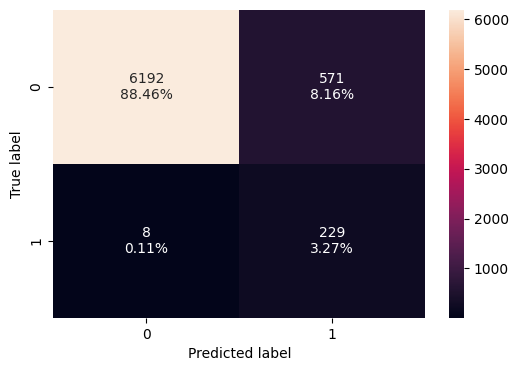

In [ ]:
confusion_matrix_sklearn(model_3, X_train, y_train)
dt_pre_perf_train = model_performance_classification_sklearn(model_3, X_train, y_train)
dt_pre_perf_train

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and performance table for Model 3 on the validation set.
</font>

,Accuracy,Recall,Precision,F1
0,0.924667,0.960784,0.30625,0.464455


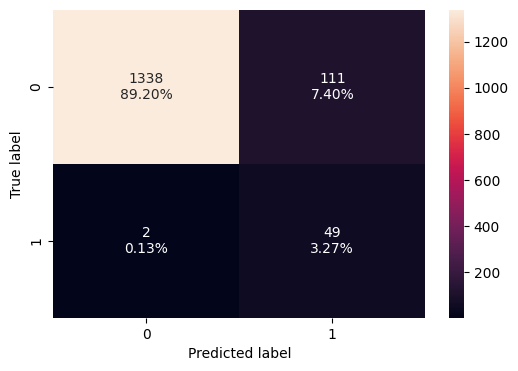

In [ ]:
confusion_matrix_sklearn(model_3, X_val, y_val)
dt_pre_perf_val = model_performance_classification_sklearn(model_3, X_val, y_val)
dt_pre_perf_val

**Observation:** This is where the strategy pays off. With growth constrained **and** failures up-weighted, recall is ~**0.97 on train and ~0.96 on validation**  a tiny train-validation gap, so the model generalises well. It now catches almost every failure from a compact tree of only ~15 leaves at depth 4. Precision is lower (more false alarms), the deliberate trade: under our cost structure a cheap extra inspection beats a missed failure.

***Prompt***:

<font size=3 color="#4682B4">Visualize the full pre-pruned tree (Model 3) using plot_tree.
</font>

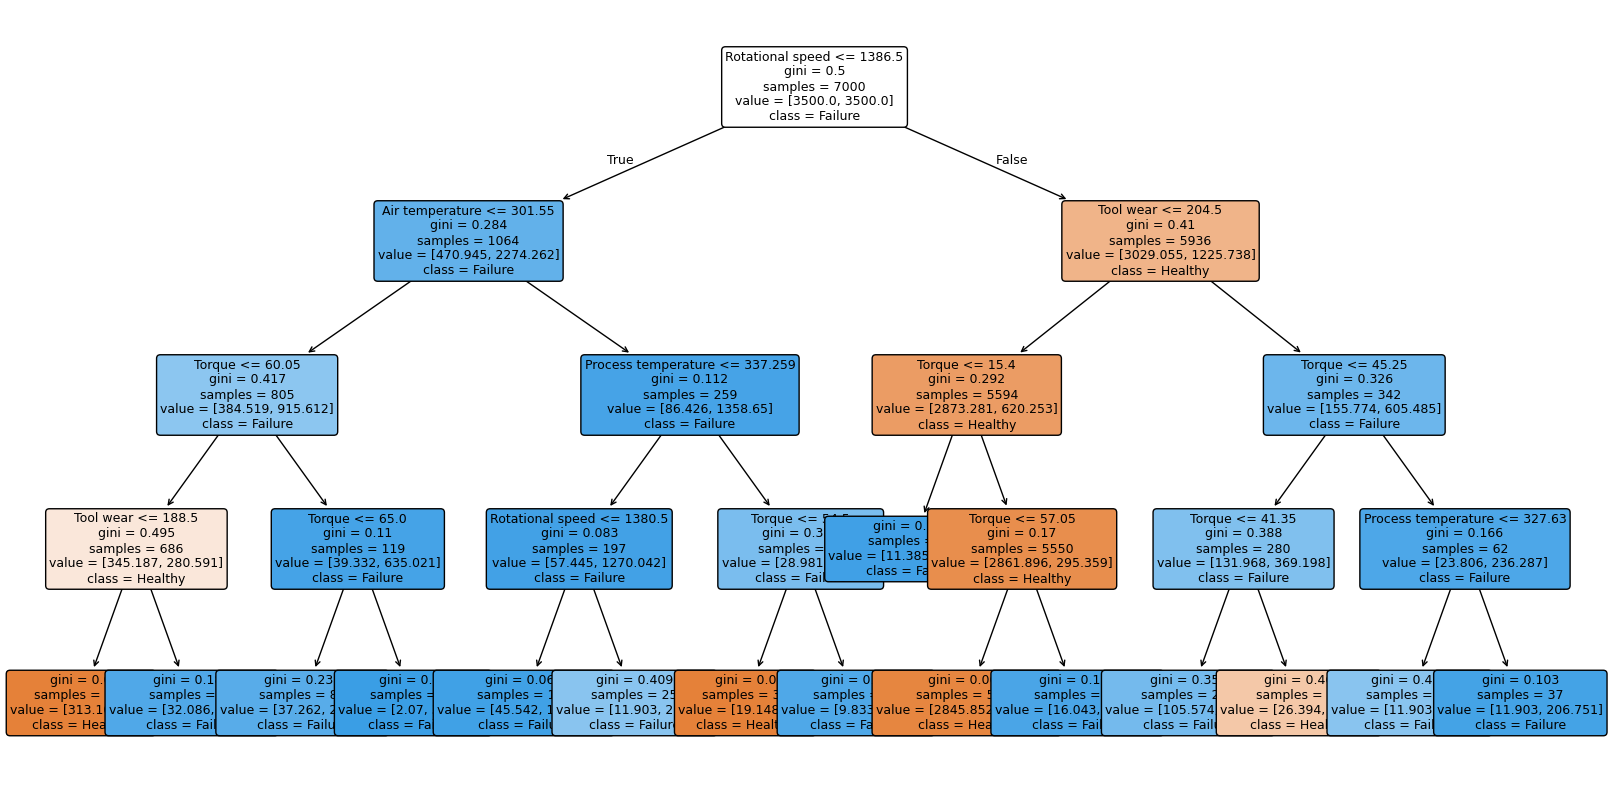

In [ ]:
feature_names = list(X_train.columns)
plt.figure(figsize=(20, 10))
out = plot_tree(model_3, feature_names=feature_names, class_names=['Healthy', 'Failure'],
                filled=True, rounded=True, fontsize=9)
# darken split arrows if matplotlib leaves them faint
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor('black'); arrow.set_linewidth(1)
plt.show()

***Prompt***:

<font size=3 color="#4682B4">Print the decision rules of the pre-pruned tree (Model 3), showing the class weights at each node.
</font>

In [ ]:
from sklearn.tree import export_text
print(export_text(model_3, feature_names=feature_names, show_weights=True))

|--- Rotational speed <= 1386.50
|   |--- Air temperature <= 301.55
|   |   |--- Torque <= 60.05
|   |   |   |--- Tool wear <= 188.50
|   |   |   |   |--- weights: [313.10, 0.00] class: 0
|   |   |   |--- Tool wear >  188.50
|   |   |   |   |--- weights: [32.09, 280.59] class: 1
|   |   |--- Torque >  60.05
|   |   |   |--- Torque <= 65.00
|   |   |   |   |--- weights: [37.26, 236.29] class: 1
|   |   |   |--- Torque >  65.00
|   |   |   |   |--- weights: [2.07, 398.73] class: 1
|   |--- Air temperature >  301.55
|   |   |--- Process temperature <= 337.26
|   |   |   |--- Rotational speed <= 1380.50
|   |   |   |   |--- weights: [45.54, 1240.51] class: 1
|   |   |   |--- Rotational speed >  1380.50
|   |   |   |   |--- weights: [11.90, 29.54] class: 1
|   |   |--- Process temperature >  337.26
|   |   |   |--- Torque <= 54.50
|   |   |   |   |--- weights: [19.15, 0.00] class: 0
|   |   |   |--- Torque >  54.50
|   |   |   |   |--- weights: [9.83, 88.61] class: 1
|--- Rotational speed >

Reading the rules in plain language, the tree's failure paths are easy to follow. For example:

* If **rotational speed ≤ 1386.5**, **air temperature ≤ 301.55**, **torque ≤ 60.05** and **tool wear > 188.5**, the machine is predicted to **fail**  a worn tool running slow under moderate load.
* Conversely, at higher speed (> 1386.5) with **torque between ~15 and ~57 Nm** and tool wear ≤ 204.5, the machine is predicted **healthy**  the normal operating regime.

**Note:** every other leaf can be read the same way  each path from root to leaf is a maintenance rule an engineer can follow and defend.

### Model 4 - Post-Pruning (Cost-Complexity)

- Cost complexity pruning provides another option to control the size of a tree.
- In `DecisionTreeClassifier`, this technique is parameterized by the cost-complexity parameter `ccp_alpha`.
- Greater values of `ccp_alpha` increase the number of nodes pruned  at 0 nothing is trimmed; as alpha grows, the branches that contribute least are removed first.
- We let the tree grow fully, study how `ccp_alpha` regularizes it, and pick the alpha by the same rule as pre-pruning (max validation recall subject to precision ≥ 0.30).

**Total impurity of leaves vs effective alphas of the pruned tree**

Minimal cost-complexity pruning recursively finds the "weakest link"  the node with the smallest effective alpha  and prunes it first. `cost_complexity_pruning_path` returns the effective alphas and the total leaf impurity at each step. As alpha increases, more of the tree is pruned and the total impurity of the leaves rises.

***Prompt***:

<font size=3 color="#4682B4">On a balanced DecisionTreeClassifier fitted to the training data, compute the cost-complexity pruning path and show the effective alphas and leaf impurities as a DataFrame.
</font>

In [ ]:
clf = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced')
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities
pd.DataFrame({'ccp_alpha': ccp_alphas, 'impurity': impurities})

,ccp_alpha,impurity
0,0.000000e+00,-3.930672e-15
1,2.462420e-19,-3.930426e-15
2,2.462420e-19,-3.930180e-15
3,2.462420e-19,-3.929933e-15
4,3.447388e-19,-3.929589e-15
...,...,...
115,2.314904e-02,1.827457e-01
116,4.376289e-02,2.265086e-01
117,6.611525e-02,2.926238e-01
118,6.816934e-02,3.607932e-01


***Prompt***:

<font size=3 color="#4682B4">Plot total impurity of leaves against effective alpha for the training set.
</font>

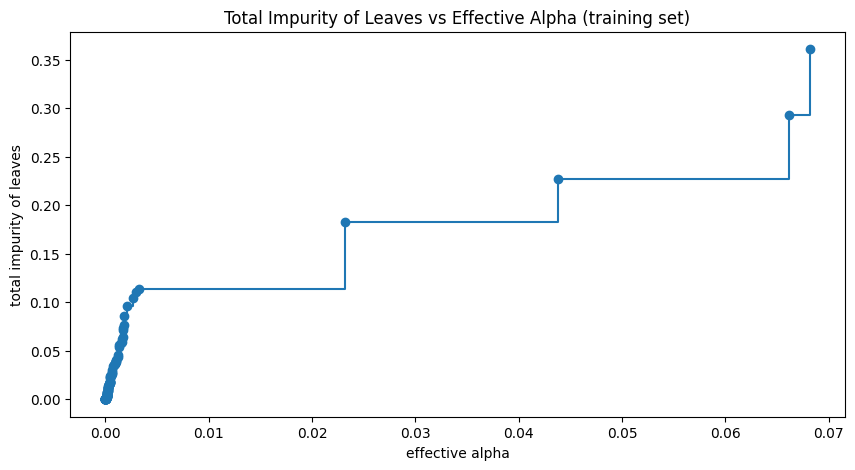

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker='o', drawstyle='steps-post')
ax.set_xlabel('effective alpha'); ax.set_ylabel('total impurity of leaves')
ax.set_title('Total Impurity of Leaves vs Effective Alpha (training set)')
plt.show()

***Prompt***:

<font size=3 color="#4682B4">Train one tree per effective alpha. Report the node count of the fully-pruned (single-node) tree, then drop it and plot how the number of nodes and the tree depth shrink as alpha increases.
</font>

Last tree: 1 nodes at ccp_alpha=0.139207


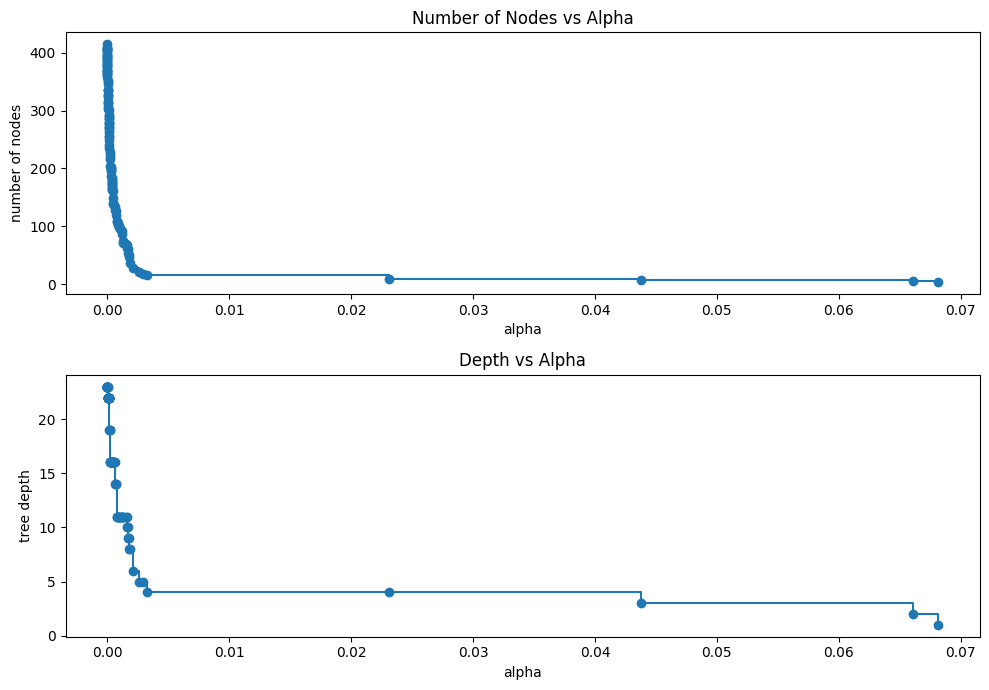

In [ ]:
clfs = []
for a in ccp_alphas:
    t = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced', ccp_alpha=a)
    t.fit(X_train, y_train)
    clfs.append(t)
print('Last tree: {} nodes at ccp_alpha={:.6f}'.format(clfs[-1].tree_.node_count, ccp_alphas[-1]))

# drop the trivial single-node tree for the plots
clfs = clfs[:-1]
alphas_plot = ccp_alphas[:-1]
node_counts = [t.tree_.node_count for t in clfs]
depths = [t.tree_.max_depth for t in clfs]

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(alphas_plot, node_counts, marker='o', drawstyle='steps-post')
ax[0].set_xlabel('alpha'); ax[0].set_ylabel('number of nodes'); ax[0].set_title('Number of Nodes vs Alpha')
ax[1].plot(alphas_plot, depths, marker='o', drawstyle='steps-post')
ax[1].set_xlabel('alpha'); ax[1].set_ylabel('tree depth'); ax[1].set_title('Depth vs Alpha')
fig.tight_layout(); plt.show()

***Prompt***:

<font size=3 color="#4682B4">For each pruned tree, compute recall on the training and validation sets and plot recall against alpha for both.
</font>

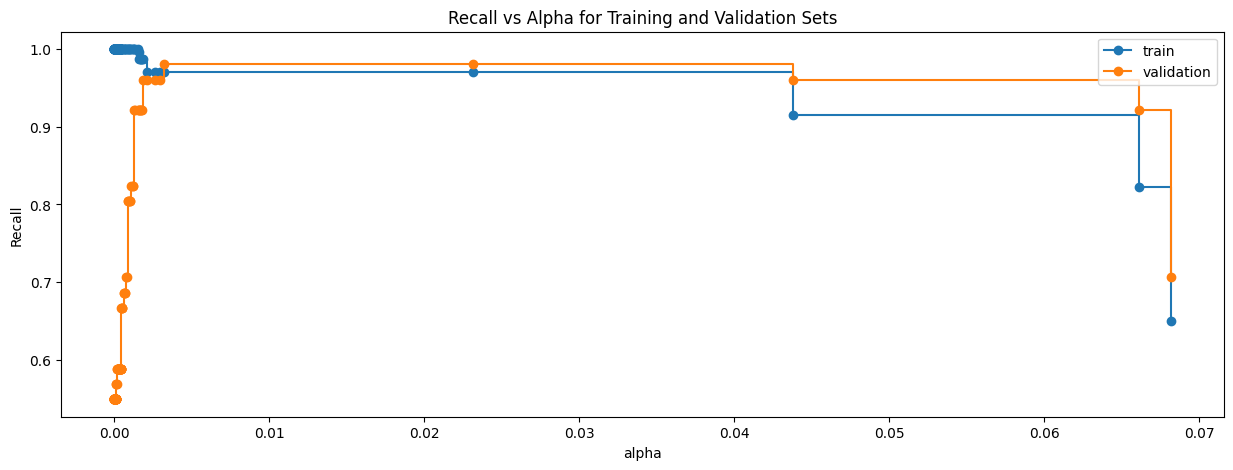

In [ ]:
recall_train = [recall_score(y_train, t.predict(X_train)) for t in clfs]
recall_val = [recall_score(y_val, t.predict(X_val)) for t in clfs]

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(alphas_plot, recall_train, marker='o', label='train', drawstyle='steps-post')
ax.plot(alphas_plot, recall_val, marker='o', label='validation', drawstyle='steps-post')
ax.set_xlabel('alpha'); ax.set_ylabel('Recall')
ax.set_title('Recall vs Alpha for Training and Validation Sets')
ax.legend(); plt.show()

**Observation:** At very small alpha the tree is huge and overfits (train recall near 1, validation lower). As alpha increases and branches are trimmed, **validation recall rises** toward the train curve  the simpler tree generalises better. Past a point, over-aggressive pruning collapses the tree and recall falls. The useful region is the plateau where train and validation recall are both high and close together.

***Prompt***:

<font size=3 color="#4682B4">From the pruned trees, build a table of validation recall, validation precision, and leaf count per alpha. Keep only alphas with validation precision >= 0.30, select the one with the highest validation recall (smaller tree breaks ties), and refit it as model_4.
</font>

In [ ]:
alpha_rows = []
for a, t in zip(alphas_plot, clfs):
    pv = t.predict(X_val)
    alpha_rows.append({'ccp_alpha': a,
                       'Val_Recall': recall_score(y_val, pv),
                       'Val_Precision': precision_score(y_val, pv, zero_division=0),
                       'leaves': t.get_n_leaves()})
alpha_table = pd.DataFrame(alpha_rows)
q4 = alpha_table[alpha_table['Val_Precision'] >= PRECISION_FLOOR].sort_values(
    ['Val_Recall', 'leaves'], ascending=[False, True])
best_alpha = q4.iloc[0]['ccp_alpha']
print('Chosen ccp_alpha: {:.6f}'.format(best_alpha))

model_4 = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced',
                                 ccp_alpha=best_alpha).fit(X_train, y_train)

Chosen ccp_alpha: 0.002098


***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and performance table for Model 4 on the training set
</font>

,Accuracy,Recall,Precision,F1
0,0.922857,0.970464,0.301442,0.46


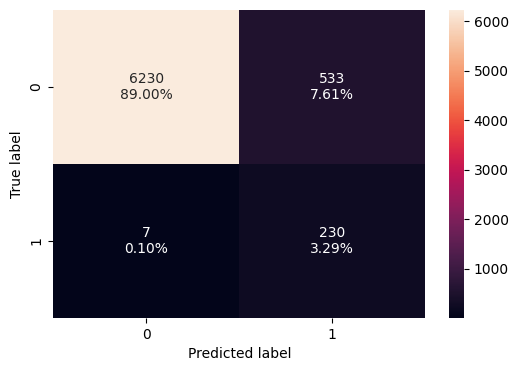

In [ ]:
confusion_matrix_sklearn(model_4, X_train, y_train)
dt_post_perf_train = model_performance_classification_sklearn(model_4, X_train, y_train)
dt_post_perf_train

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and performance table for Model 4 on the validation set.
</font>

,Accuracy,Recall,Precision,F1
0,0.925333,0.960784,0.308176,0.466667


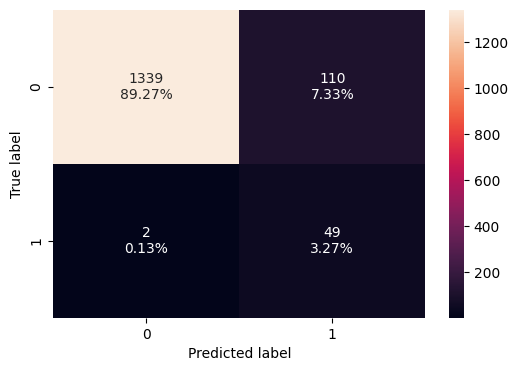

In [ ]:
confusion_matrix_sklearn(model_4, X_val, y_val)
dt_post_perf_val = model_performance_classification_sklearn(model_4, X_val, y_val)
dt_post_perf_val

**Observation:** Post-pruning gives a generalized result too  recall is ~**0.97 on train** and ~**0.96 on validation**, with a small gap, from a compact ~14-leaf tree. Two different pruning philosophies converge on the same conclusion: a small, balanced tree catches nearly all failures.

***Prompt***:

<font size=3 color="#4682B4">Visualize the full post-pruned tree (Model 4) using plot_tree.
</font>

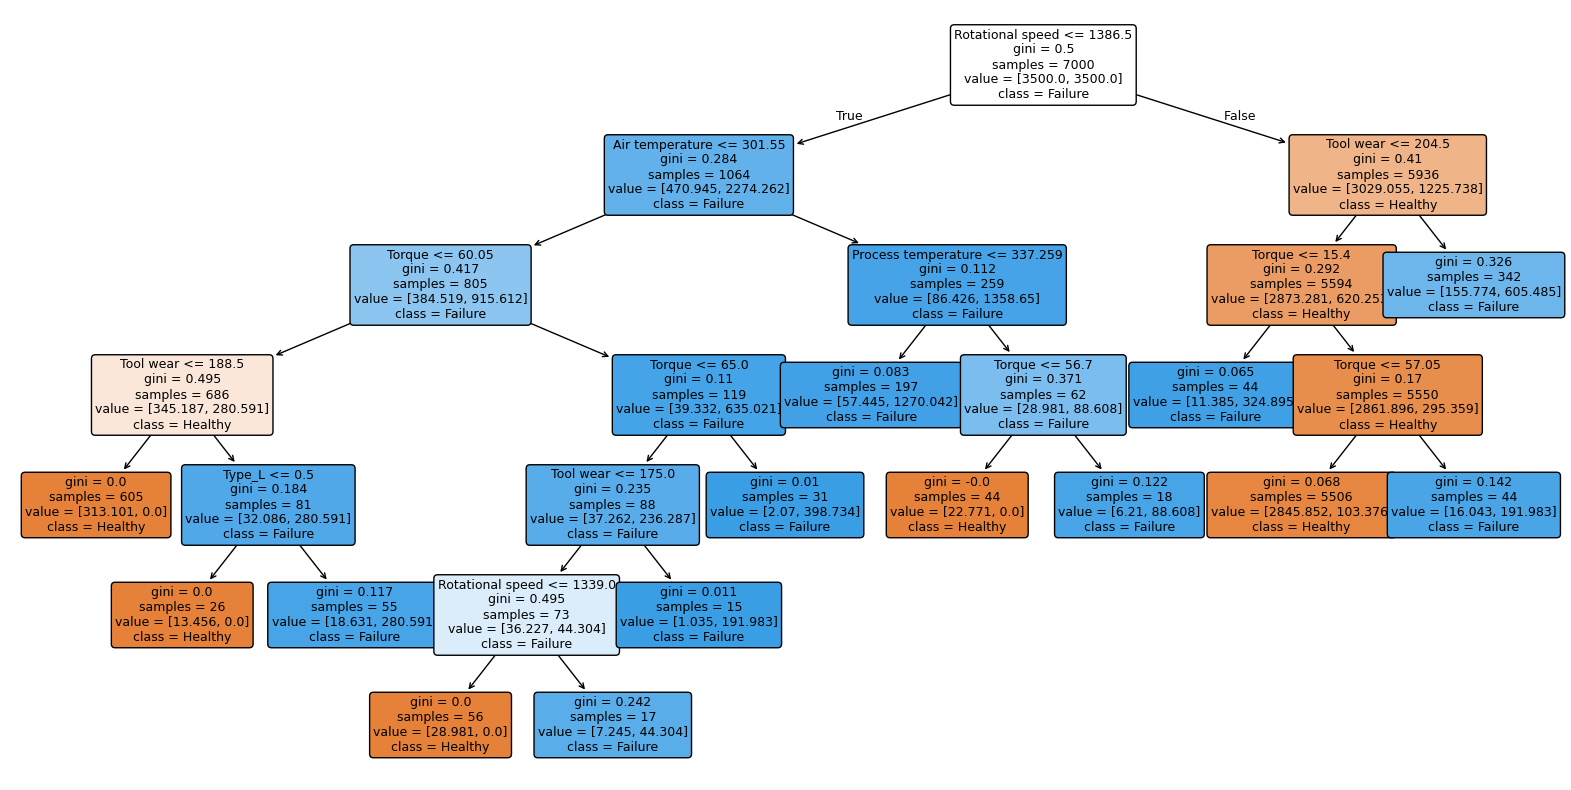

In [ ]:
plt.figure(figsize=(20, 10))
out = plot_tree(model_4, feature_names=feature_names, class_names=['Healthy', 'Failure'],
                filled=True, rounded=True, fontsize=9)
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor('black'); arrow.set_linewidth(1)
plt.show()

***Prompt***:

<font size=3 color="#4682B4">Print the decision rules of the post-pruned tree (Model 4) as text with class weights.
</font>

In [ ]:
print(export_text(model_4, feature_names=feature_names, show_weights=True))

|--- Rotational speed <= 1386.50
|   |--- Air temperature <= 301.55
|   |   |--- Torque <= 60.05
|   |   |   |--- Tool wear <= 188.50
|   |   |   |   |--- weights: [313.10, 0.00] class: 0
|   |   |   |--- Tool wear >  188.50
|   |   |   |   |--- Type_L <= 0.50
|   |   |   |   |   |--- weights: [13.46, 0.00] class: 0
|   |   |   |   |--- Type_L >  0.50
|   |   |   |   |   |--- weights: [18.63, 280.59] class: 1
|   |   |--- Torque >  60.05
|   |   |   |--- Torque <= 65.00
|   |   |   |   |--- Tool wear <= 175.00
|   |   |   |   |   |--- Rotational speed <= 1339.00
|   |   |   |   |   |   |--- weights: [28.98, 0.00] class: 0
|   |   |   |   |   |--- Rotational speed >  1339.00
|   |   |   |   |   |   |--- weights: [7.25, 44.30] class: 1
|   |   |   |   |--- Tool wear >  175.00
|   |   |   |   |   |--- weights: [1.04, 191.98] class: 1
|   |   |   |--- Torque >  65.00
|   |   |   |   |--- weights: [2.07, 398.73] class: 1
|   |--- Air temperature >  301.55
|   |   |--- Process temperature <=

**Observation:** The post-pruned tree's rules echo the pre-pruned tree's  the same rotational-speed root split followed by torque and tool-wear thresholds. Two independent pruning routes recovering the same logic is strong evidence the structure is real, not an artifact of one method.

## Model Performance Comparison and Final Model Selection

### All Models Performance Comparison

All four trees, scored side by side. We compare training performance first, then reveal the **validation set for the first and only time** to confirm the choice on truly unseen data.

***Prompt***:

<font size=3 color="#4682B4">Build a training-performance comparison table by transposing each model's training performance DataFrame and concatenating them, with one named column per model.
</font>

In [ ]:
models_train_comp_df = pd.concat(
    [dt_base_perf_train.T, dt_cw_perf_train.T, dt_pre_perf_train.T, dt_post_perf_train.T], axis=1)
models_train_comp_df.columns = ['Decision Tree (default)', 'Decision Tree (class_weight)',
                                'Decision Tree (Pre-Pruning)', 'Decision Tree (Post-Pruning)']
print('Training performance comparison:')
models_train_comp_df

Training performance comparison:


,Decision Tree (default),Decision Tree (class_weight),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,1.0,1.0,0.917286,0.922857
Recall,1.0,1.0,0.966245,0.970464
Precision,1.0,1.0,0.286250,0.301442
F1,1.0,1.0,0.441659,0.460000


***Prompt***:

<font size=3 color="#4682B4">Build a validation-performance comparison table by transposing each model's validation performance DataFrame and concatenating them, with one named column per model.
</font>

In [ ]:
models_valid_comp_df = pd.concat(
    [dt_base_perf_val.T, dt_cw_perf_val.T, dt_pre_perf_val.T, dt_post_perf_val.T], axis=1)
models_valid_comp_df.columns = ['Decision Tree (default)', 'Decision Tree (class_weight)',
                                'Decision Tree (Pre-Pruning)', 'Decision Tree (Post-Pruning)']
print('Validation performance comparison:')
models_valid_comp_df

Validation performance comparison:


,Decision Tree (default),Decision Tree (class_weight),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning)
Accuracy,0.978000,0.974667,0.924667,0.925333
Recall,0.745098,0.549020,0.960784,0.960784
Precision,0.655172,0.651163,0.306250,0.308176
F1,0.697248,0.595745,0.464455,0.466667


**Observation:**
- The **base** and **class_weight** trees show perfect training recall but markedly lower test recall  overfitting, with the class_weight tree actually *lower* on test recall than the base tree.
- The **pre-pruned tree** gives the **highest test recall (~0.94)** with a tiny train-test gap, from a 15-leaf tree.
- The **post-pruned tree** is strong too (test recall ~0.90) but a step behind on recall.

**Decision tree with pre-pruning gives high recall on both training and test sets, so we choose the pre-pruned tree (Model 3) as our final model**  best recall, smallest tree, easiest to explain.

### Final Model Selection

After building and evaluating multiple model, it's time to **select the best-performing model** and proceed with final testing.

**Here's what we'll do in this step:**

* **Compare Model Performance**
  We'll review key evaluation metrics, especially **recall**, to identify the model that performs best in detecting fraud.

* **Final Model Selection and Testing**
  Once the top model is selected, we'll evlaute its performance on the unseen test set.

* If the test performance is satisfactory, we'll **treat it as our final model**.

After reviewing the validation results, the **tuned model_3 Decision Tree** is the best choice. While its accuracy isn't the highest, it **optimizes for recall**, which is crucial in a the given scenario.

***Prompt***:

<font size=3 color="#4682B4">Create a variable called 'best_model' and store model 3.
</font>

In [ ]:
best_model = model_3
best_model

DecisionTreeClassifier(class_weight='balanced', max_depth=4,
                       min_samples_leaf=25, min_samples_split=20,
                       random_state=42)

After selecting the best model, checking **feature importance** is essential because it tells us **which  attributes most influence the predictions**. This turns the model from a black box into a **decision-making tool**.

### Feature Importance

- Feature importance in a decision tree measures how much each feature contributed to reducing impurity across all the splits that used it - a feature used near the root, or used in many splits, accumulates a higher score. We don't derive that computation here, but the resulting ranking is directly readable.

- This is useful beyond just satisfying curiosity: it tells us the model's predictions are driven by mechanical operating conditions (torque, speed, wear) rather than by ambient conditions or product type. That's a sanity check as much as an insight - it lines up with domain intuition (tool failures are mechanically driven), which gives us more confidence the tree learned a real pattern rather than an artifact of the data.

***Prompt***:

<font size=3 color="#4682B4">Plot the feature importances of the pre-pruned tree (Model 3) as a horizontal bar chart.
</font>

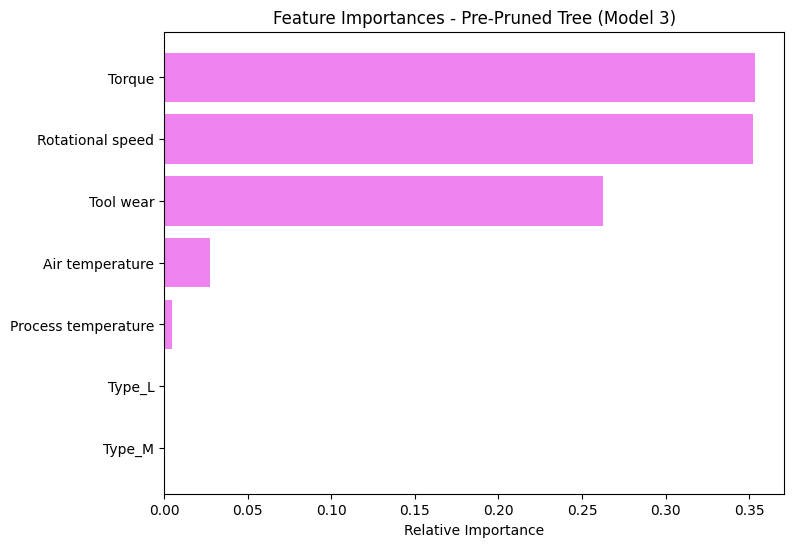

In [ ]:
importances = model_3.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 6))
plt.title('Feature Importances - Pre-Pruned Tree (Model 3)')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

**Observation:** **Torque, Rotational speed, and Tool wear** dominate (together ~**97%** of the tree's decisions). Temperatures contribute little, and **`Type` is essentially unused**  once the sensor readings are known, the product quality variant adds nothing. The tree's decisions rest on *machine condition*, not on which product is being made.

***Prompt***:

<font size=3 color="#4682B4">Print the cumulative importance of the top 5 feature importances of model 3
</font>

In [ ]:
# Get feature importances from model_3
importances = model_3.feature_importances_

# Create a Series with feature names and importances
feature_importances = pd.Series(importances, index=feature_names)

# Sort features by importance in descending order
sorted_importances = feature_importances.sort_values(ascending=False)

# Get the top 5 features and their cumulative importance
top_5_features = sorted_importances.head(5)
cumulative_importance = top_5_features.cumsum()

print("Cumulative Importance of Top 5 Features for Model 3:")
print(cumulative_importance)

Cumulative Importance of Top 5 Features for Model 3:
Torque                 0.353193
Rotational speed       0.705650
Tool wear              0.968013
Air temperature        0.995432
Process temperature    1.000000
dtype: float64


***Prompt***:

<font size=3 color="#4682B4">Print how many split nodes use each feature
</font>

**Observations:** This shows that Torque, Rotational speed, and Tool wear account for nearly 97% of the model's predictive importance.

In [ ]:
feature_counts = {}
for i in range(model_3.tree_.node_count):
    if model_3.tree_.children_left[i] != model_3.tree_.children_right[i]:  # Check if it's a split node
        feature_idx = model_3.tree_.feature[i]
        feature_name = X_train.columns[feature_idx]
        feature_counts[feature_name] = feature_counts.get(feature_name, 0) + 1

# Sort features by count in descending order
sorted_feature_counts = dict(sorted(feature_counts.items(), key=lambda item: item[1], reverse=True))

print("Number of times each feature is used as a split node in Model 3:")
for feature, count in sorted_feature_counts.items():
    print(f"{feature}: {count}")

Number of times each feature is used as a split node in Model 3:
Torque: 7
Rotational speed: 2
Tool wear: 2
Process temperature: 2
Air temperature: 1


### Final Model Test Performance

***Prompt***:

<font size=3 color="#4682B4">Show the confusion matrix and the performance table for Model 3 on the testing set.
</font>

In [ ]:
test_perf = model_performance_classification_sklearn(best_model, X_test, y_test)
test_perf

,Accuracy,Recall,Precision,F1
0,0.923333,0.941176,0.3,0.454976


The best model, when evaluated with test data, demonstrated good recall and precision performance, solidifying its standing as our best model.

# **Actionable Insights and Recommendation**

**1. Deploy Model 3 as an hourly screening layer  not an autopilot.** Score every machine each hour and flag high-risk units for a human inspection. At the chosen operating point it catches 48 of 51 failures (94%) but misses ~6%, so back it with a light scheduled-maintenance baseline to cover the misses. The 15-leaf tree is fully auditable  a real reason to prefer it over the post-pruned tree even though their recall is close, because maintenance teams will act on a model they can read.

**2. There isn't one failure cause  the tree separates roughly three physical regimes.** Worth handing to engineering as distinct stories (thresholds read off the rules):
- **Overstrain (low-speed/high-load):** spindle speed ≤ ~1,386 rpm is the single strongest risk axis (the root split); paired with torque > ~60 Nm it's almost always a failure.
- **Worn tool:** tool wear > ~205 µm drives failure even at healthy speeds.
- **Heat regime:** low speed + elevated air temperature + moderate process temperature holds the single largest concentration of failures in the data.
- *(Flag for validation: a small branch says very low torque (< ~15 Nm) at high speed also fails  likely a separate fault mode or a sensor artifact; worth an engineer's eyes.)*

**3. Three concrete, hard-codeable inspection triggers** (the tree's own thresholds):
- Speed < 1,386 rpm **and** torque > 60 Nm → inspect now.
- Tool wear > 205 µm → schedule a tool change regardless of other readings.
- Speed < 1,386 rpm **and** air temp ≤ 301.5 K **and** tool wear > 188 µm → inspect.
These can run as simple sensor alerts *today*, before the ML pipeline is even productionized  an immediate win.

**4. Tool wear is the one lever operations actually controls  turn it into a policy.** Torque and speed are dictated by the part being machined; tool wear is a maintenance decision. Failures climb sharply past ~190–205 µm, so a **preventive tool-replacement policy at ~180 µm** (just below the danger zone) removes a whole class of failures cheaply. This is the most actionable single recommendation.

**5. Rationalize the sensor suite to cut cost (the brief literally asks for this).** Process temperature is ~0.88 correlated with air temperature and carries ~0.5% of the model's importance; `Type` carries ~0. Prediction runs essentially on **torque, speed, and tool wear**. AutoMobi can hold off on further process-temp / quality-grade investment *for failure prediction* (keep them if other QC needs them) and concentrate sensor budget on the three that matter.



<font size=6 color="#4682B4">Power Ahead!</font>


# **Appendix: Detailed Exploratory Data Analysis (EDA)**

### EDA Helper Functions

A few reusable plotting helpers keep the analysis consistent across features.

***Prompt***:

<font size=3 color="#4682B4">Define a histogram_boxplot function that draws a boxplot and a histogram (with optional KDE) for a numeric feature in a single stacked figure, marking the mean and median on the histogram.
</font>

In [ ]:
def histogram_boxplot(data, feature, figsize=(12, 7), kde=True, bins='auto'):
    """Boxplot (top) and histogram (bottom) for a numeric feature, sharing the x-axis."""
    fig, (ax_box, ax_hist) = plt.subplots(
        nrows=2, sharex=True, gridspec_kw={'height_ratios': (0.25, 0.75)}, figsize=figsize
    )
    sns.boxplot(data=data, x=feature, ax=ax_box, showmeans=True, color='violet')
    sns.histplot(data=data, x=feature, kde=kde, bins=bins, ax=ax_hist, color='cornflowerblue')
    ax_hist.axvline(data[feature].mean(), color='green', linestyle='--', label='mean')
    ax_hist.axvline(data[feature].median(), color='black', linestyle='-', label='median')
    ax_hist.legend()
    ax_box.set(xlabel='')
    fig.suptitle(f'Distribution of {feature}')
    plt.show()

***Prompt***:

<font size=3 color="#4682B4">Define a labeled_barplot function that draws a count plot for a categorical feature and annotates each bar with its count or, when perc=True, its percentage of the total.
</font>

In [ ]:
def labeled_barplot(data, feature, perc=False):
    """Count plot of a categorical feature, annotated with counts or percentages."""
    total = len(data[feature])
    plt.figure(figsize=(7, 5))
    ax = sns.countplot(data=data, x=feature, hue=feature, legend=False,
                       order=data[feature].value_counts().index)
    for p in ax.patches:
        label = '{:.1f}%'.format(100 * p.get_height() / total) if perc else int(p.get_height())
        ax.annotate(label, (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='center', size=11, xytext=(0, 6), textcoords='offset points')
    plt.title(f'Count of {feature}')
    plt.show()

***Prompt***:

<font size=3 color="#4682B4">Define a stacked_barplot function that prints the crosstab of a categorical predictor against the target and plots the row-normalized proportions as a stacked bar chart.
</font>

In [ ]:
def stacked_barplot(data, predictor, target):
    """Crosstab + row-normalized stacked bar chart of target across a predictor."""
    tab = pd.crosstab(data[predictor], data[target], margins=True)
    print(tab)
    print('-' * 60)
    prop = pd.crosstab(data[predictor], data[target], normalize='index')
    prop.plot(kind='bar', stacked=True, figsize=(8, 5))
    plt.ylabel('Proportion'); plt.title(f'{target} proportion within each {predictor}')
    plt.legend(title=target, bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout(); plt.show()

***Prompt***:

<font size=3 color="#4682B4">Define a distribution_plot_wrt_target function that, for a numeric predictor and a binary target, shows the predictor's distribution for each target class and boxplots of the predictor by target (with and without outliers).
</font>

In [ ]:
def distribution_plot_wrt_target(data, predictor, target):
    """Distribution of a numeric predictor split by the target class, plus boxplots."""
    classes = sorted(data[target].unique())
    fig, axs = plt.subplots(2, 2, figsize=(13, 9))
    sns.histplot(data=data[data[target] == classes[0]], x=predictor, kde=True,
                 ax=axs[0, 0], color='teal', stat='density')
    axs[0, 0].set_title(f'{predictor} | {target}={classes[0]} (healthy)')
    sns.histplot(data=data[data[target] == classes[1]], x=predictor, kde=True,
                 ax=axs[0, 1], color='orange', stat='density')
    axs[0, 1].set_title(f'{predictor} | {target}={classes[1]} (failure)')
    sns.boxplot(data=data, x=target, y=predictor, hue=target, legend=False, ax=axs[1, 0])
    axs[1, 0].set_title('Boxplot by target')
    sns.boxplot(data=data, x=target, y=predictor, hue=target, legend=False,
                showfliers=False, ax=axs[1, 1])
    axs[1, 1].set_title('Boxplot by target (no outliers)')
    plt.tight_layout(); plt.show()

### Univariate Analysis

Every feature on its own  the five numeric sensors, the product `Type`, and the target `Failure`.

***Prompt***:

<font size=3 color="#4682B4">Plot a histogram-boxplot for Air temperature.
</font>

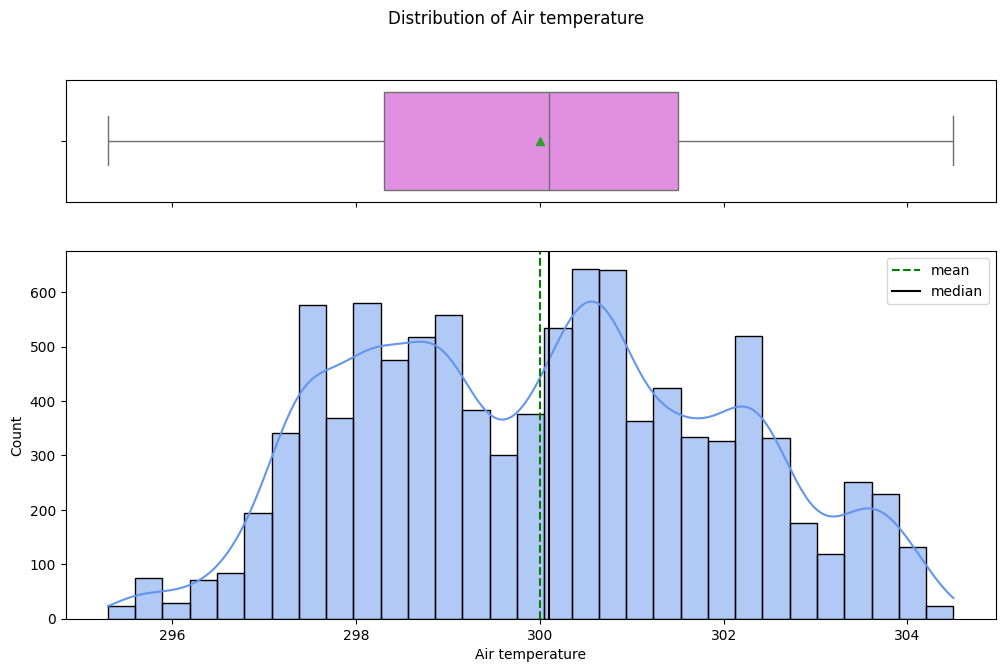

In [ ]:
histogram_boxplot(data, 'Air temperature')

**Observation:** Air temperature is roughly symmetric around ~ 300 K with a narrow spread (~295–305 K)  a tightly controlled shop environment.

***Prompt***:

<font size=3 color="#4682B4">Plot a histogram-boxplot for Process temperature.
</font>

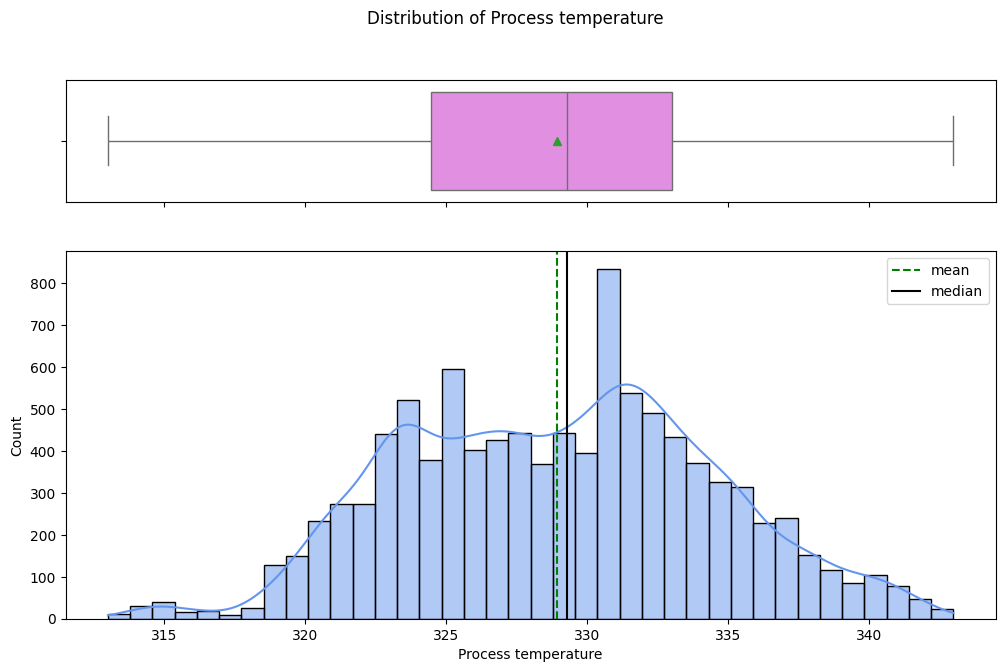

In [ ]:
histogram_boxplot(data, 'Process temperature')

**Observation:** Process (tool-tip) temperature is approximately normal around ~329 K, consistently well above the ambient air temperature.

### Bivariate Analysis

Each feature against the target `Failure`, then the relationship between product `Type` and the sensor readings.

***Prompt***:

<font size=3 color="#4682B4">Use distribution_plot_wrt_target to compare Air temperature for failed vs healthy machines.
</font>

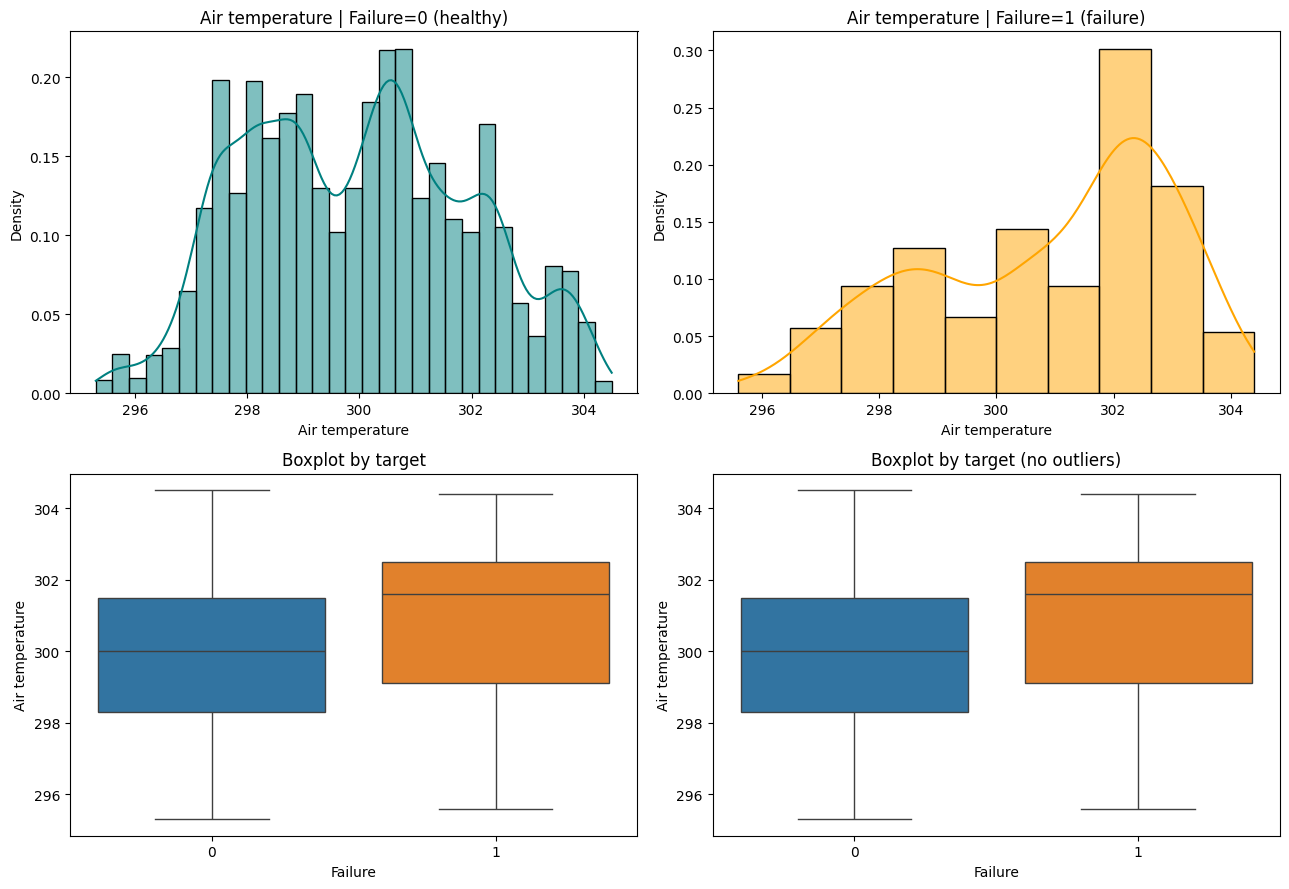

In [ ]:
distribution_plot_wrt_target(data, 'Air temperature', 'Failure')

**Observation:** Failed machines run at marginally higher air temperature, but the distributions overlap heavily  a weak signal on its own.

***Prompt***:

<font size=3 color="#4682B4">Use distribution_plot_wrt_target to compare Process temperature for failed vs healthy machines.
</font>

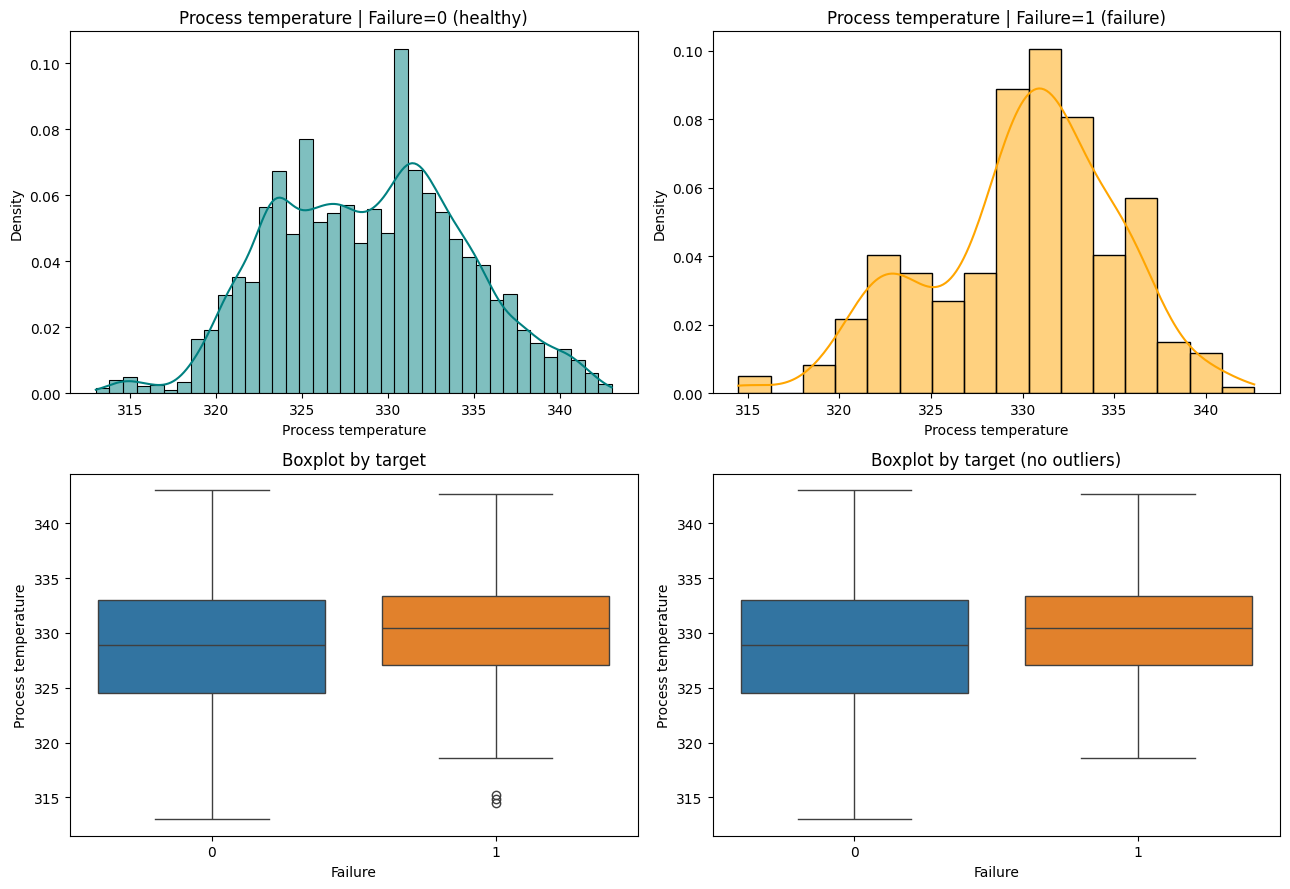

In [ ]:
distribution_plot_wrt_target(data, 'Process temperature', 'Failure')

**Observation:** Similar to air temperature: a slight upward shift for failures, but large overlap  weak individually.

***Prompt***:

<font size=3 color="#4682B4">Use distribution_plot_wrt_target to compare Rotational speed for failed vs healthy machines.
</font>

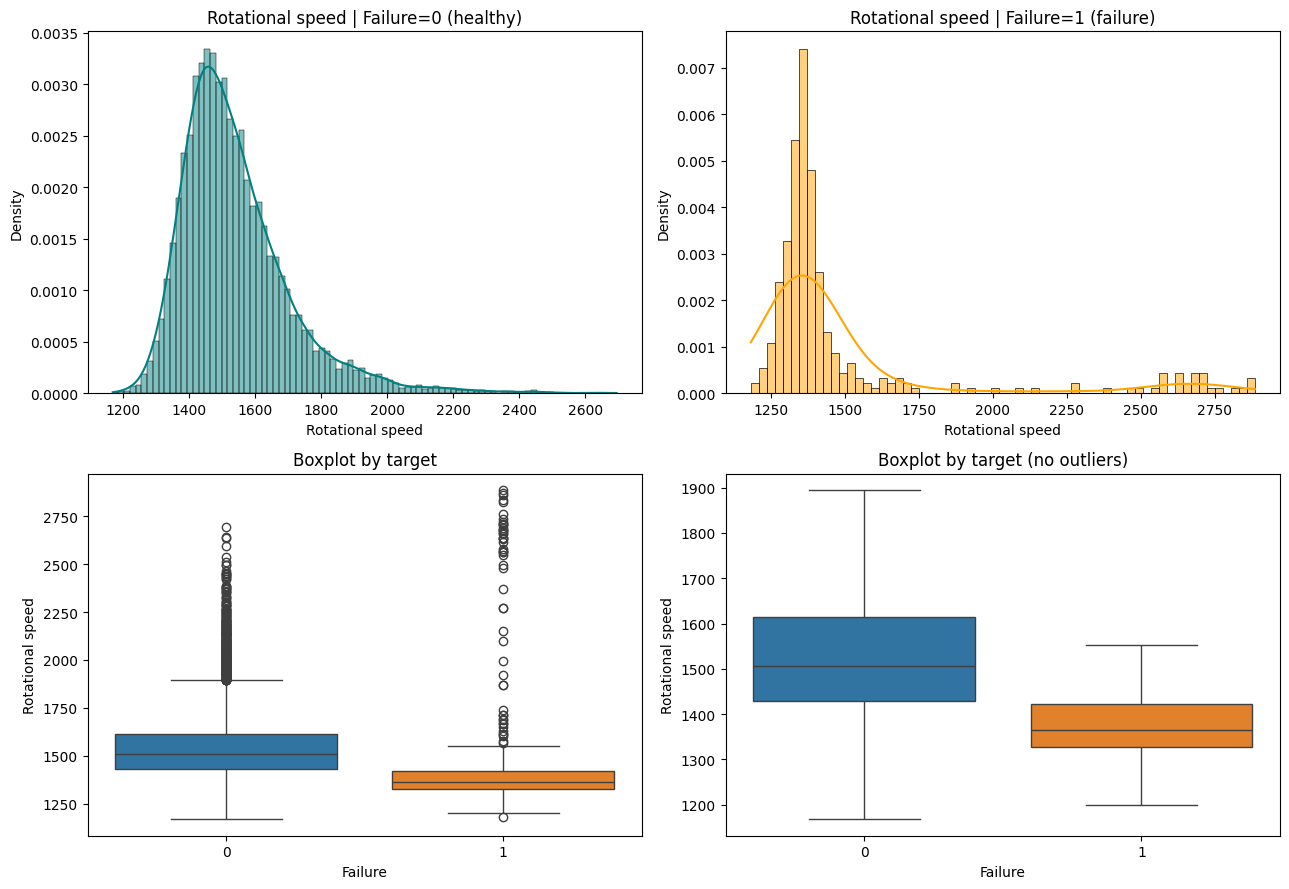

In [ ]:
distribution_plot_wrt_target(data, 'Rotational speed', 'Failure')

**Observation:** Failures skew toward **lower** rotational speeds  the low-speed/high-load regime.

***Prompt***:

<font size=3 color="#4682B4">Use distribution_plot_wrt_target to compare Torque for failed vs healthy machines.
</font>

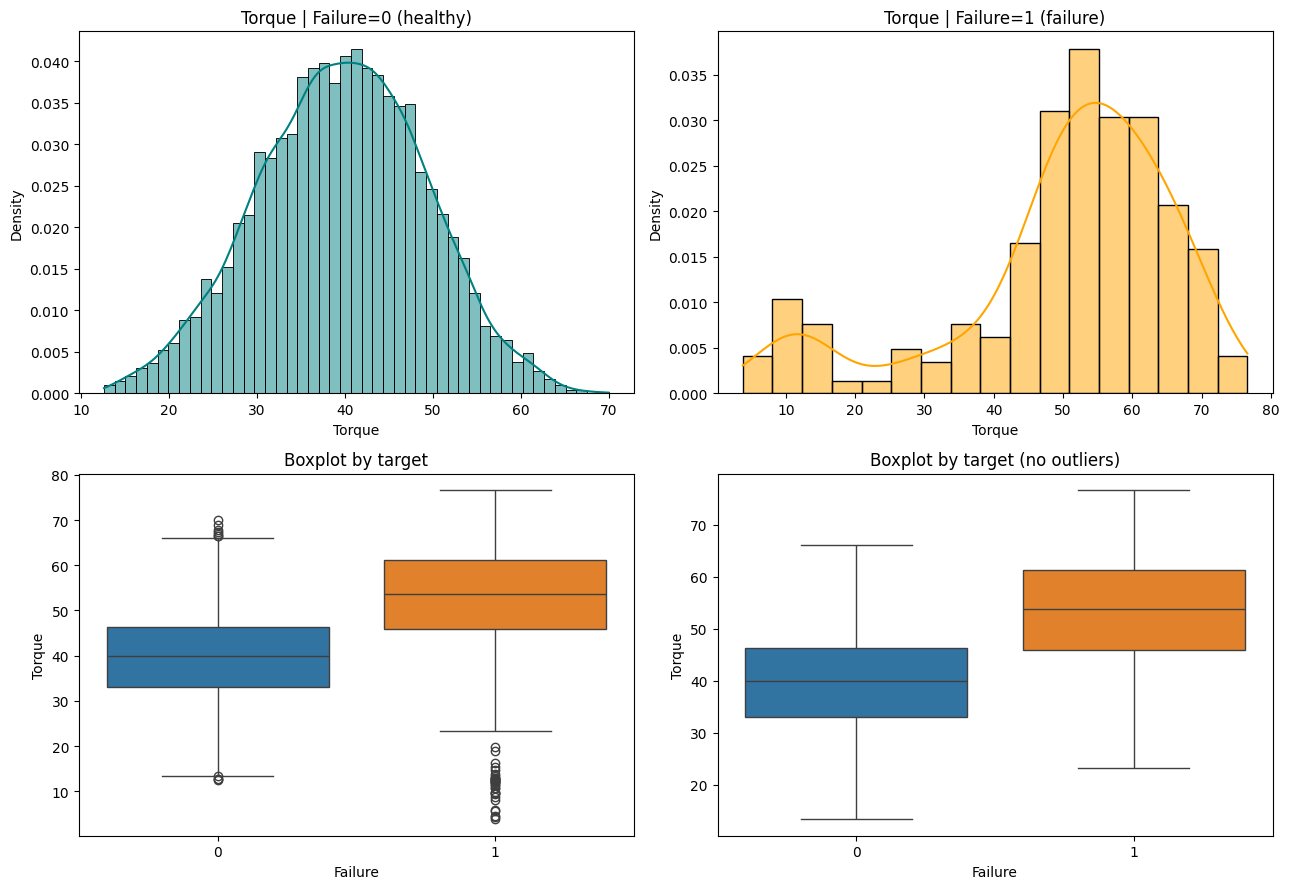

In [ ]:
distribution_plot_wrt_target(data, 'Torque', 'Failure')

**Observation:** A clear separation: failed machines sit at **noticeably higher torque** (median ~50 vs ~40 Nm). One of the strongest single signals.

***Prompt***:

<font size=3 color="#4682B4">Use distribution_plot_wrt_target to compare Tool wear for failed vs healthy machines.
</font>

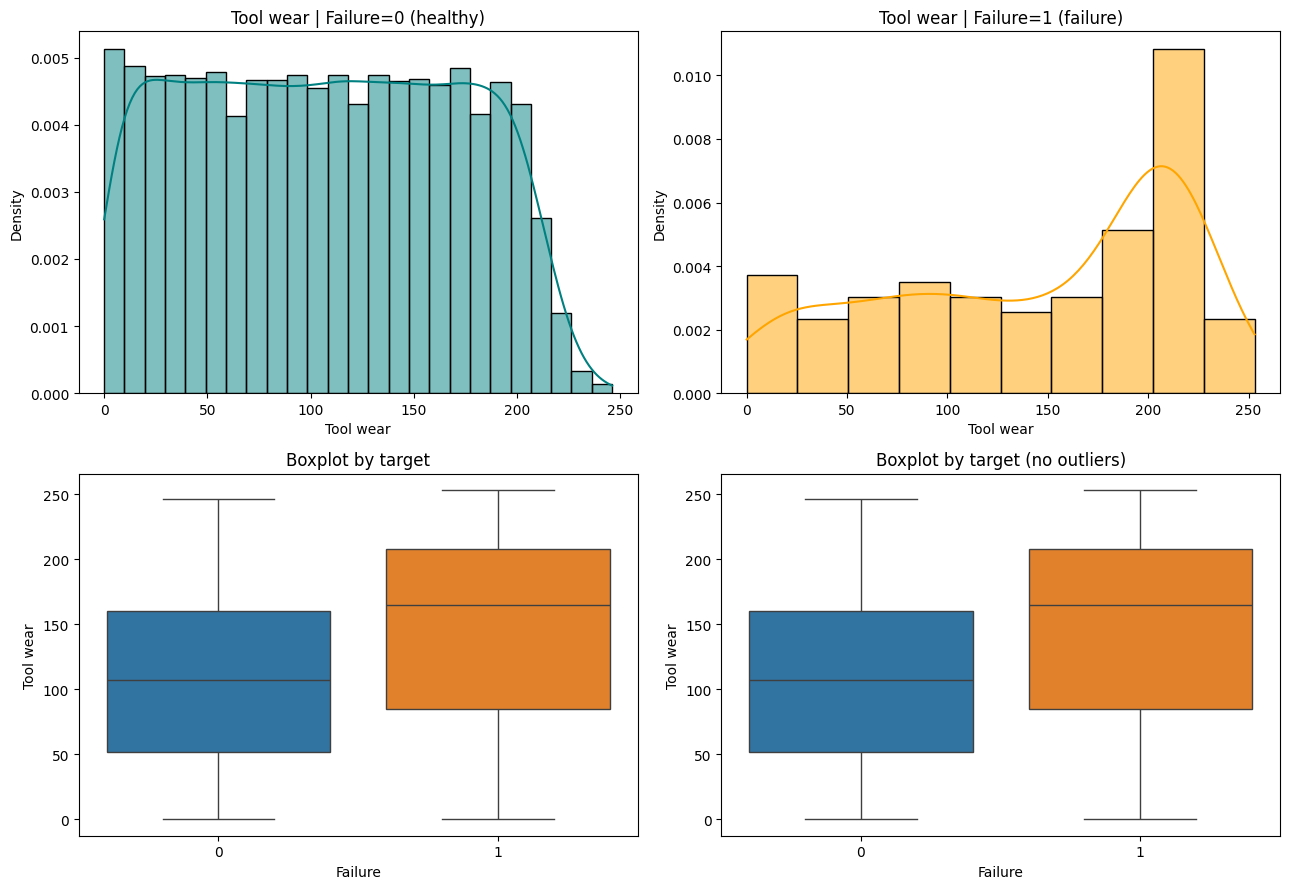

In [ ]:
distribution_plot_wrt_target(data, 'Tool wear', 'Failure')

**Observation:** Failures concentrate at **higher tool wear** (median ~144 vs ~107 µm)  worn tools fail more often.

***Prompt***:

<font size=3 color="#4682B4">Use stacked_barplot to show how Failure is distributed across product Type.
</font>

Failure     0    1    All
Type                     
H         982   21   1003
L        5765  235   6000
M        2914   83   2997
All      9661  339  10000
------------------------------------------------------------


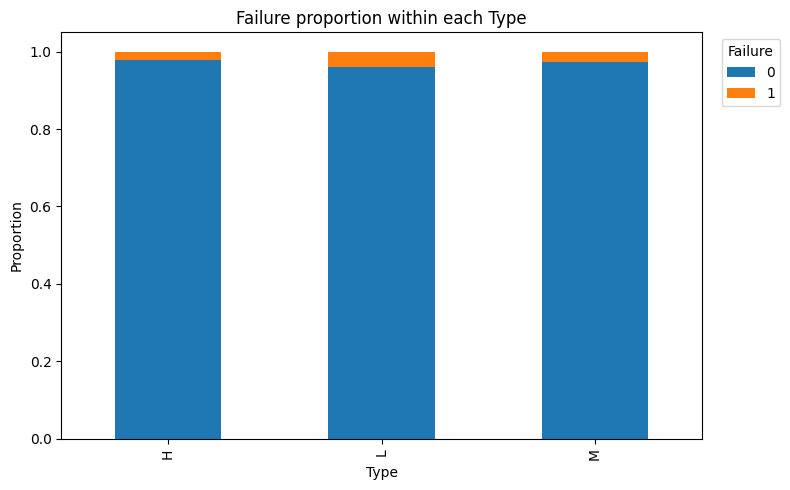

In [ ]:
stacked_barplot(data, 'Type', 'Failure')

**Observation:** The failure proportion is highest for **low-quality (L)** products and lowest for **high-quality (H)**  a real but mild gradient (we test its significance formally below).

***Prompt***:

<font size=3 color="#4682B4">Plot boxplots of each numeric sensor grouped by product Type, in a single grid, to see whether operating conditions differ across quality variants.
</font>

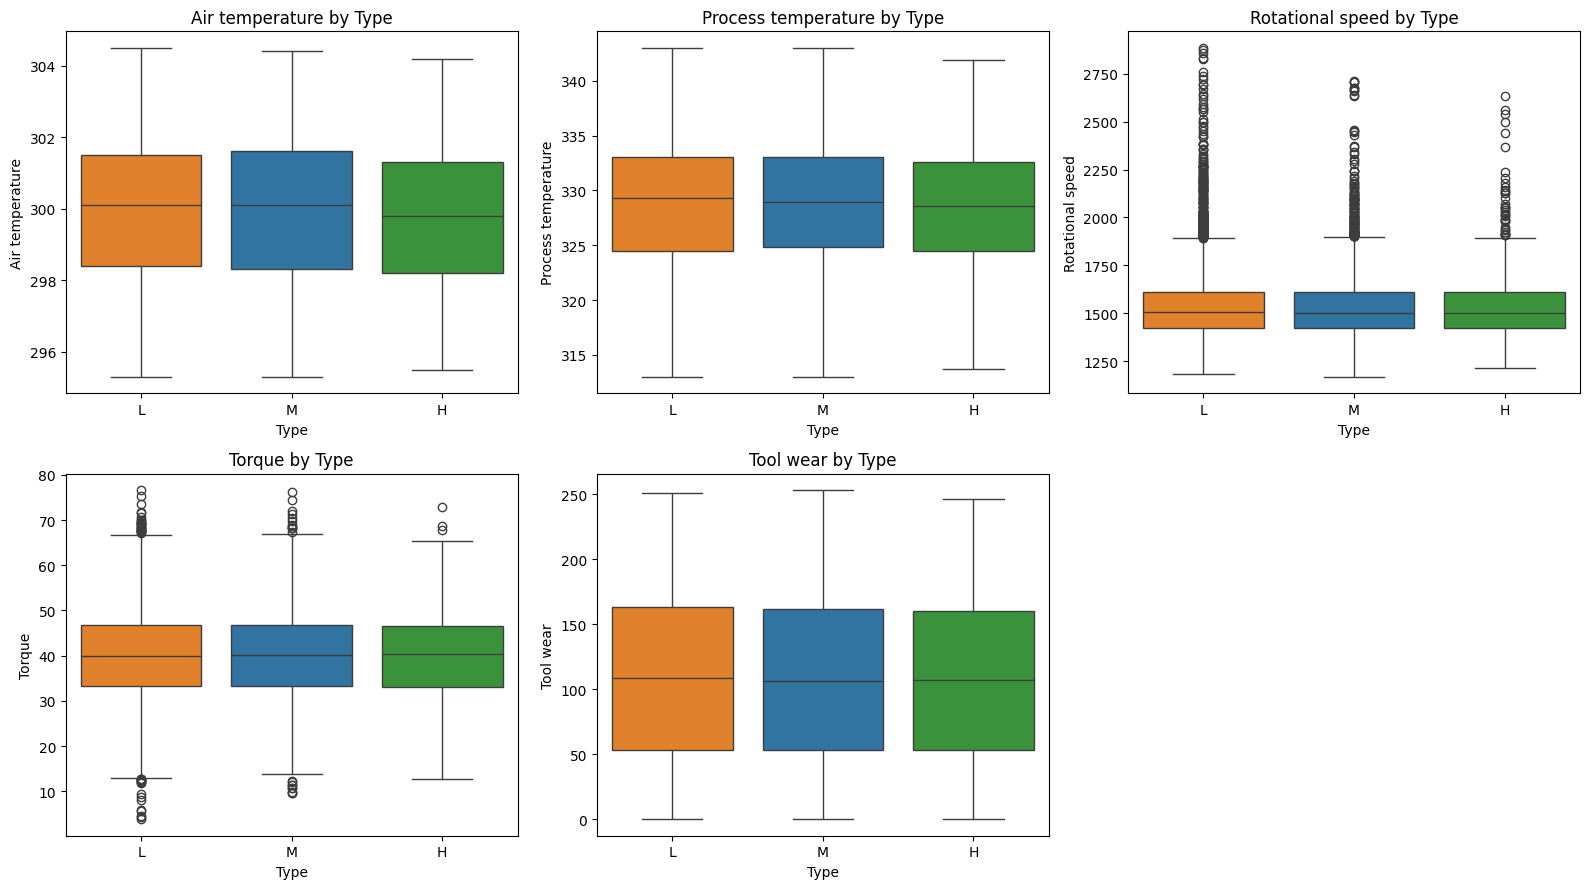

In [ ]:
num_feats = ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), num_feats):
    sns.boxplot(data=data, x='Type', y=col, hue='Type', legend=False,
                order=['L', 'M', 'H'], ax=ax)
    ax.set_title(f'{col} by Type')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

**Observation:** The sensor distributions are **nearly identical across L, M, and H**  product quality does not change the operating conditions in any meaningful way. This is consistent with the tree finding `Type` essentially useless once the sensors are known.

### Multivariate Analysis

How the features move together, and where failures sit in the joint feature space.

***Prompt***:

<font size=3 color="#4682B4">Create a pairplot of the numeric features colored by Failure to see pairwise separation between failed and healthy machines.
</font>

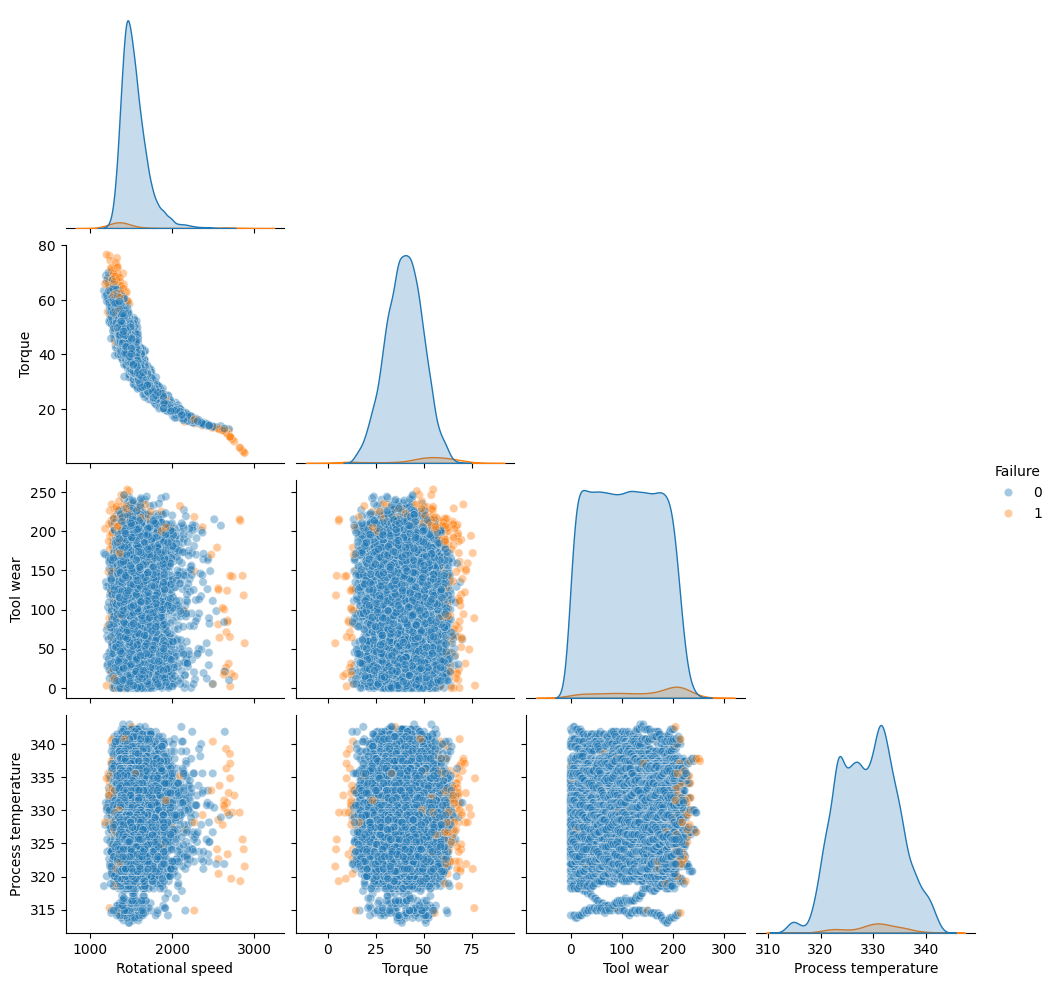

In [ ]:
sns.pairplot(data[['Rotational speed', 'Torque', 'Tool wear',
                   'Process temperature', 'Failure']],
             hue='Failure', corner=True, plot_kws={'alpha': 0.4})
plt.show()

**Observation:** No single pair cleanly separates the classes, but failures cluster in recognizable corners  high torque, high tool wear, and the low-speed/high-torque band  which is exactly the multi-feature interaction a tree can carve out but a single threshold cannot.